# 2024 年全国大学生数学建模竞赛 A 题　「“板凳龙”闹元宵」　求解与结果

本 Notebook 按 `reports/ANALYSIS_MODELING_REPORT.md` 的建模方案逐问实现、运行、校验并作图。

**统一建模口径**

- 径向等距阿基米德螺线 $r=r_0-b\sigma/(2\pi)=r_0-k\theta$，$k=b/(2\pi)$，$r_0=16b$；
- 224 个把手节点、223 条刚性连杆，孔距为连杆长度：龙头 2.86 m，其余 1.65 m，链总长 369.16 m；
- 龙头 $H_0$ 沿路径以给定弧速前进，其余节点由**刚性弦长约束** $|P(s_i)-P(s_{i-1})|=\ell_i$ 逆运动方向递推求解（$s_i<s_{i-1}$，即后续节点在龙头外侧）；
- 速度由弦长约束对时间求导解析得到：$v_i=v_{i-1}a_i,\ a_i=\dfrac{u_i\cdot T_{i-1}}{u_i\cdot T_i}$；
- 碰撞采用非相邻板凳矩形的 SAT（分离轴）判定，相邻板凳豁免。

**运行顺序**：环境自检 → 几何引擎 → 问题一 → 问题二 → 问题三 → 问题四 → 问题五 → 灵敏度分析。

## 0　运行环境与依赖自检

先确认解释器、第三方库版本、中文字体与数据文件是否就绪；任一项缺失会在本单元直接报错，避免后续误算。

In [1]:
import sys, os, math, json, time, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import ticker as mticker
import openpyxl

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "test" / "A题").exists():
        ROOT = cand
        break
CODE = ROOT / "code"
OUT = CODE / "outputs"
FIG = ROOT / "figures"
for d in (OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["mathtext.fontset"] = "dejavusans"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"

TPL = {
    "result1": ROOT / "test" / "A题" / "附件" / "result1.xlsx",
    "result2": ROOT / "test" / "A题" / "附件" / "result2.xlsx",
    "result4": ROOT / "test" / "A题" / "附件" / "result4.xlsx",
}

print("Python      :", sys.version.split()[0], platform.architecture()[0])
print("NumPy       :", np.__version__)
print("SciPy       :", scipy.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("openpyxl    :", openpyxl.__version__)
print("工作目录    :", ROOT)
missing = [str(p) for p in TPL.values() if not p.exists()]
assert not missing, f"缺少附件模板: {missing}"

from matplotlib import font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_cjk = [n for n in ("SimHei", "Microsoft YaHei", "SimSun") if n in _avail]
print("中文字体    :", _cjk)
assert _cjk, "未找到中文字体，图表中文将显示为乱码"

Python      : 3.14.4 64bit
NumPy       : 2.5.4
SciPy       : 1.18.1
pandas      : 3.0.6
matplotlib  : 3.11.2
openpyxl    : 3.1.5
工作目录    : D:\shumo
中文字体    : ['SimHei', 'Microsoft YaHei', 'SimSun']


In [2]:
# 读取三个模板的结构，确认节点标签、时间轴与行列数（仅用于输出格式对齐）
def read_template(path):
    wb = openpyxl.load_workbook(path)
    info = {}
    for ws in wb.worksheets:
        times = [ws.cell(1, c).value for c in range(2, ws.max_column + 1)]
        labels = [ws.cell(r, 1).value for r in range(2, ws.max_row + 1)]
        info[ws.title] = dict(shape=(ws.max_row, ws.max_column), times=times, labels=labels)
    return info

TPL_INFO = {k: read_template(p) for k, p in TPL.items()}
for k, v in TPL_INFO.items():
    for sh, info in v.items():
        print(f"{k:8s} / {sh:4s}  行×列={info['shape']}  时间列 {len(info['times'])} 个 "
              f"[{info['times'][0]} … {info['times'][-1]}]")
print()
print("节点标签（前 4 个）:", TPL_INFO["result2"]["Sheet1"]["labels"][:4])
print("节点标签（后 2 个）:", TPL_INFO["result2"]["Sheet1"]["labels"][-2:])
NODE_LABELS = TPL_INFO["result2"]["Sheet1"]["labels"]
assert len(NODE_LABELS) == 224 and NODE_LABELS[0] == "龙头" and NODE_LABELS[-1] == "龙尾（后）"
print("\n模板校验通过：224 个把手节点，与 1 龙头 + 221 龙身 + 龙尾(前) + 龙尾(后) 一致。")

result1  / 位置    行×列=(449, 302)  时间列 301 个 [0 s … 300 s]
result1  / 速度    行×列=(225, 302)  时间列 301 个 [0 s … 300 s]
result2  / Sheet1  行×列=(225, 4)  时间列 3 个 [横坐标x (m) … 速度 (m/s)]
result4  / 位置    行×列=(449, 202)  时间列 201 个 [-100 s … 100 s]
result4  / 速度    行×列=(225, 202)  时间列 201 个 [-100 s … 100 s]

节点标签（前 4 个）: ['龙头', '第1节龙身', '第2节龙身', '第3节龙身']
节点标签（后 2 个）: ['龙尾', '龙尾（后）']

模板校验通过：224 个把手节点，与 1 龙头 + 221 龙身 + 龙尾(前) + 龙尾(后) 一致。


## 1　统一几何与运动学引擎

### 1.1 解析弧长与螺线参数化

令 $G(r)=\dfrac r2\sqrt{r^2+k^2}+\dfrac{k^2}{2}\operatorname{arsinh}\dfrac rk$，则从 $r_0$ 向内走过的弧长为

$$s=\frac{G(r_0)-G(r)}{k}\quad\Longleftrightarrow\quad G(r)=G(r_0)-k\,s .$$

给定 $s$ 时用牛顿法反解 $r$（$G$ 严格单调递增）；转角 $\theta=(r_0-r)/k$，位置与单位切向

$$P=\bigl(r\cos\theta,\,-r\sin\theta\bigr),\qquad
T=\frac{\bigl(-k\cos\theta-r\sin\theta,\;k\sin\theta-r\cos\theta\bigr)}{\sqrt{r^2+k^2}} .$$

$s>0$ 向内（半径变小），$s<0$ 向外（半径变大），因此螺线在 $A$ 点外侧需继续延伸以容纳 369.16 m 长链。

In [3]:
N_BOARD = 223          # 板凳数
N_NODE = 224           # 把手节点数
LEN_HEAD = 2.86        # 龙头孔距
LEN_BODY = 1.65        # 龙身/龙尾孔距
ELL = np.array([LEN_HEAD] + [LEN_BODY] * 222)     # ELL[i] 连接 H_i 与 H_{i+1}
W_BOARD = 0.30         # 板宽
HALF_W = W_BOARD / 2
OVERHANG = 0.275       # 孔中心到板端
R_CIRCLE = 4.5         # 调头空间半径

print("板凳数 %d，节点数 %d，连杆数 %d" % (N_BOARD, N_NODE, len(ELL)))
print("链总长 = %.2f m （= %.2f + 222×%.2f）" % (ELL.sum(), LEN_HEAD, LEN_BODY))
assert abs(ELL.sum() - 369.16) < 1e-12


class Spiral:
    """径向等距阿基米德螺线 r = r0 - k*theta，s 为自 A 点起沿运动方向（向内为正）的弧长。"""

    __slots__ = ("b", "k", "r0", "G0")

    def __init__(self, b, r0=None):
        self.b = float(b)
        self.k = self.b / (2 * math.pi)
        self.r0 = 16.0 * b if r0 is None else float(r0)
        self.G0 = self.G(self.r0)

    def G(self, r):
        k = self.k
        return 0.5 * r * math.hypot(r, k) + 0.5 * k * k * math.asinh(r / k)

    def radius(self, s, guess=None):
        """由弧长 s 反解半径 r（牛顿迭代）。"""
        target = self.G0 - self.k * s
        if target <= 0.0:
            raise ValueError("弧长超出螺线可容纳范围")
        r = guess if (guess and guess > 0) else max(math.sqrt(2.0 * target), 1e-3)
        k = self.k
        for _ in range(80):
            f = self.G(r) - target
            d = math.hypot(r, k)
            rn = r - f / d
            if rn <= 1e-12:
                rn = 0.5 * r
            if abs(rn - r) <= 2e-15 * max(1.0, r):
                r = rn
                break
            r = rn
        return r

    def state(self, s, guess=None):
        """返回 (r, P, T)。"""
        r = self.radius(s, guess)
        th = (self.r0 - r) / self.k
        c, sn = math.cos(th), math.sin(th)
        L = math.hypot(r, self.k)
        P = (r * c, -r * sn)
        T = ((-self.k * c - r * sn) / L, (self.k * sn - r * c) / L)
        return r, P, T

    def pos(self, s, guess=None):
        return self.state(s, guess)[1]

    def tangent(self, s, guess=None):
        return self.state(s, guess)[2]


# --- 单元自检：解析弧长与数值积分一致性 ---
_sp = Spiral(0.55)
_rng = np.random.default_rng(0)
_err = 0.0
for _ in range(20):
    _r = _rng.uniform(2.0, 12.0)
    _s = (_sp.G(_sp.r0) - _sp.G(_r)) / _sp.k
    _err = max(_err, abs(_sp.radius(_s) - _r))
print("螺线反解半径的最大误差 = %.2e m" % _err)
assert _err < 1e-9

# 切向单位性与差分一致性
_h = 1e-6
_e1 = max(abs(np.hypot(*_sp.tangent(_s)) - 1.0) for _s in np.linspace(-50, 50, 7))
_e2 = max(abs((_sp.pos(_s + _h)[0] - _sp.pos(_s - _h)[0]) / (2 * _h) - _sp.tangent(_s)[0])
          for _s in np.linspace(-50, 50, 7))
print("|T|-1 = %.2e,  切向与差分一致性 %.2e" % (_e1, _e2))
assert _e1 < 1e-12 and _e2 < 1e-6

板凳数 223，节点数 224，连杆数 223
链总长 = 369.16 m （= 2.86 + 222×1.65）
螺线反解半径的最大误差 = 1.78e-15 m
|T|-1 = 1.11e-16,  切向与差分一致性 5.23e-08


### 1.2 弦长递推、速度放大与碰撞几何

给定龙头弧长 $s_0$ 与上一节点 $P(s_{i-1})$，解一元方程

$$h_i(s)=\bigl|P(s)-P(s_{i-1})\bigr|^2-\ell_i^2=0,\qquad s<s_{i-1}$$

采用「上一时刻解热启动 + 牛顿迭代 + 二分兜底」。速度由隐函数求导得到 $a_i=\dfrac{u_i\cdot T_{i-1}}{u_i\cdot T_i}$，$A_i=\prod_{k\le i}a_k$。

板凳 $j$ 的检测矩形由 $H_jH_{j+1}$ 两端外延 0.275 m、法向半宽 0.15 m 构成；非相邻矩形用 8 条边法向的 SAT 投影判断分离，`pen = min_axis( min(maxA,maxB)-max(minA,minB) )` 为最小平移重叠量（负值即间隙）。

In [4]:
def solve_chain(spiral, s0, ell=ELL, warm=None, guess_r=None):
    """由龙头弧长 s0 递推全链 224 个节点的 s、位置与单位切向。"""
    n = len(ell) + 1
    s = [0.0] * n
    X = [(0.0, 0.0)] * n
    Tg = [(0.0, 0.0)] * n
    r_arr = [0.0] * n

    r0_, p0, t0 = spiral.state(s0, guess_r)
    s[0], X[0], Tg[0], r_arr[0] = s0, p0, t0, r0_
    gr = r0_

    for i in range(1, n):
        li = ell[i - 1]
        prev = X[i - 1]
        px, py = prev
        if warm is not None:
            # 热启动：沿用上一时刻同一连杆的弧长间隔，避免在强弯曲段跳到另一支根
            gs = s[i - 1] - (warm[i - 1] - warm[i])
        else:
            # 首时刻：用局部曲率半径估计弧长步长（圆弧上精确）
            _r1, _p1, _t1 = spiral.state(s[i - 1])
            _r2, _p2, _t2 = spiral.state(s[i - 1] - 1e-3)
            kap = math.hypot(_t2[0] - _t1[0], _t2[1] - _t1[1]) / 1e-3
            if 1e-9 < kap and kap * li / 2 < 0.999:
                gs = s[i - 1] - 2.0 / kap * math.asin(kap * li / 2.0)
            else:
                gs = s[i - 1] - li
        # --- 牛顿迭代 ---
        si = gs
        ok = False
        for _ in range(16):
            r, p, t = spiral.state(si, gr)
            dx, dy = p[0] - px, p[1] - py
            h = dx * dx + dy * dy - li * li
            if abs(h) < 1e-12 * li:
                ok = True
                break
            d = 2.0 * (dx * t[0] + dy * t[1])
            if d == 0.0:
                break
            sn = si - h / d
            if not (s[i - 1] - 2.6 * li < sn < s[i - 1]) or abs(sn - si) < 1e-14:
                si = sn if (s[i - 1] - 2.6 * li < sn < s[i - 1]) else si
                ok = abs(h) < 1e-9
                break
            si = sn
        if not ok:
            # --- 二分兜底：在 [s_{i-1}-2.4ℓ, s_{i-1}-0.35ℓ] 内找符号变化 ---
            lo, hi = s[i - 1] - 2.4 * li, s[i - 1] - 0.35 * li
            plo = spiral.pos(lo)
            phi_p = spiral.pos(hi)
            flo = (plo[0] - px) ** 2 + (plo[1] - py) ** 2 - li * li
            fhi = (phi_p[0] - px) ** 2 + (phi_p[1] - py) ** 2 - li * li
            if flo > 0 > fhi:
                for _ in range(90):
                    mid = 0.5 * (lo + hi)
                    pm = spiral.pos(mid)
                    fm = (pm[0] - px) ** 2 + (pm[1] - py) ** 2 - li * li
                    if fm > 0:
                        lo = mid
                    else:
                        hi = mid
                    if hi - lo < 1e-13:
                        break
                si = 0.5 * (lo + hi)
            else:
                si = gs
        r, p, t = spiral.state(si, gr)
        s[i], X[i], Tg[i], r_arr[i] = si, p, t, r
        gr = r
    return np.array(s), np.array(X), np.array(Tg), np.array(r_arr)


def chain_speeds(X, Tg, v0=1.0, ell=ELL):
    """由弦长约束求导得到各节点速率 v_i = A_i v0。"""
    v = np.empty(len(X))
    A = np.empty(len(X))
    v[0], A[0] = v0, 1.0
    for i in range(1, len(X)):
        li = ell[i - 1]
        ux = (X[i, 0] - X[i - 1, 0]) / li
        uy = (X[i, 1] - X[i - 1, 1]) / li
        num = ux * Tg[i - 1, 0] + uy * Tg[i - 1, 1]
        den = ux * Tg[i, 0] + uy * Tg[i, 1]
        a = num / den if abs(den) > 1e-14 else float("nan")
        v[i] = v[i - 1] * a
        A[i] = A[i - 1] * a
    return v, A


def board_quads(X, ell=ELL, half_w=HALF_W):
    """每块板凳的四个顶点（外延 0.275 m、法向半宽 half_w）。"""
    n = len(X) - 1
    quads = []
    centers = np.empty((n, 2))
    for j in range(n):
        x0, y0 = X[j]
        x1, y1 = X[j + 1]
        dx, dy = x1 - x0, y1 - y0
        L = math.hypot(dx, dy)
        ux, uy = dx / L, dy / L
        nx, ny = -uy, ux
        ax, ay = x0 - OVERHANG * ux, y0 - OVERHANG * uy
        bx, by = x1 + OVERHANG * ux, y1 + OVERHANG * uy
        quads.append(((ax + half_w * nx, ay + half_w * ny),
                      (bx + half_w * nx, by + half_w * ny),
                      (bx - half_w * nx, by - half_w * ny),
                      (ax - half_w * nx, ay - half_w * ny)))
        centers[j] = (0.5 * (ax + bx), 0.5 * (ay + by))
    return quads, centers


def _sat_pen(qa, qb, cut=-1e9):
    """两矩形的 SAT 最小重叠量；<0 表示分离（间隙 = -pen）。"""
    best = 1e18
    for q in (qa, qb):
        for e in range(4):
            x1, y1 = q[e]
            x2, y2 = q[(e + 1) % 4]
            ax, ay = -(y2 - y1), (x2 - x1)
            L = math.hypot(ax, ay)
            ax, ay = ax / L, ay / L
            amin, amax = 1e18, -1e18
            bmin, bmax = 1e18, -1e18
            for (px, py) in qa:
                d = px * ax + py * ay
                amin = d if d < amin else amin
                amax = d if d > amax else amax
            for (px, py) in qb:
                d = px * ax + py * ay
                bmin = d if d < bmin else bmin
                bmax = d if d > bmax else bmax
            pen = (amax if amax < bmax else bmax) - (amin if amin > bmin else bmin)
            if pen < best:
                best = pen
                if best < cut:
                    return best
    return best


def min_clearance(X, cut_pen=-1e9, ell=ELL, half_w=HALF_W):
    """全链非相邻板凳的最小间隙（>0 安全）与对应的最小重叠量。"""
    quads, centers = board_quads(X, ell, half_w)
    n = len(quads)
    cell = 3.6
    grid = {}
    for k in range(n):
        key = (int(math.floor(centers[k, 0] / cell)), int(math.floor(centers[k, 1] / cell)))
        grid.setdefault(key, []).append(k)
    best = -1e18
    pair = (-1, -1)
    for (cx, cy), members in grid.items():
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                other = grid.get((cx + dx, cy + dy))
                if not other:
                    continue
                for i in members:
                    for j in other:
                        if j <= i or abs(i - j) < 2:
                            continue
                        pen = _sat_pen(quads[i], quads[j], max(cut_pen, best) if best > cut_pen else cut_pen)
                        if pen > best:
                            best = pen
                            pair = (i, j)
    return -best, pair, best


# --- 单元自检：弦长残差 ---
_sp = Spiral(0.55)
_s, _X, _T, _r = solve_chain(_sp, 0.0)
_d = np.hypot(*(_X[1:] - _X[:-1]).T)
_res = np.abs(_d - ELL)
print("初始时刻弦长残差最大 = %.3e m；龙头 %.6f，尾端 r = %.6f m" % (_res.max(), _r[0], _r[-1]))
print("初始时刻各节点半径严格递增（龙尾在最外侧）:", bool(np.all(np.diff(_r) > 0)))
assert _res.max() < 1e-9 and _r[-1] > _r[0]

初始时刻弦长残差最大 = 4.707e-13 m；龙头 8.800000，尾端 r = 11.922130 m
初始时刻各节点半径严格递增（龙尾在最外侧）: True


## 2　问题一：300 s 内全队位置与速度

取 $b=0.55$ m、$r_0=16b=8.8$ m、$v_0=1$ m/s，$t=0,1,\dots,300$ s 共 301 个时刻。每个时刻以 $s_0=t$ 驱动，向后递推 223 个节点，并用解析速度公式求速率；输出写入 `result1.xlsx` 的两个工作表（与附件模板同结构、6 位小数）。

In [5]:
T1 = np.arange(0, 301, 1)
sp1 = Spiral(0.55)

S1 = np.empty((len(T1), N_NODE))
X1 = np.empty((len(T1), N_NODE, 2))
V1 = np.empty((len(T1), N_NODE))
R1 = np.empty((len(T1), N_NODE))
A1 = np.empty((len(T1), N_NODE))

warm = None
t_start = time.time()
for it, tt in enumerate(T1):
    s, X, Tg, rr = solve_chain(sp1, float(tt), warm=warm)
    v, A = chain_speeds(X, Tg, 1.0)
    S1[it], X1[it], V1[it], R1[it], A1[it] = s, X, v, rr, A
    warm = s

print("问题一仿真完成，用时 %.1f s" % (time.time() - t_start))

# ---- 校验 ----
chord_all = np.hypot(X1[:, 1:, 0] - X1[:, :-1, 0], X1[:, 1:, 1] - X1[:, :-1, 1])
chord_err = np.abs(chord_all - ELL).max()
head_v_err = np.abs(V1[:, 0] - 1.0).max()
mono = np.all(np.diff(R1, axis=1) > 0)
print("最大弦长残差        : %.3e m" % chord_err)
print("龙头速率偏差        : %.3e m/s" % head_v_err)
print("节点半径沿链递增    :", bool(mono))
print("速率范围            : %.6f ~ %.6f m/s" % (V1.min(), V1.max()))
assert chord_err < 1e-9 and head_v_err < 1e-12 and mono

# 中心差分校验速度（取 t=150 s）
_h = 1e-4
_sa, _Xa, _Ta, _ = solve_chain(sp1, 150 - _h)
_sb, _Xb, _Tb, _ = solve_chain(sp1, 150 + _h)
_fd = np.hypot(*(_Xb - _Xa).T) / (2 * _h)
_it = int(np.where(T1 == 150)[0][0])
_rel = np.abs(_fd - V1[_it]) / np.maximum(np.abs(V1[_it]), 1e-9)
print("t=150 s 中心差分速度最大相对误差: %.3e" % _rel.max())
assert _rel.max() < 1e-4

问题一仿真完成，用时 1.1 s
最大弦长残差        : 4.876e-13 m
龙头速率偏差        : 0.000e+00 m/s
节点半径沿链递增    : True
速率范围            : 0.996478 ~ 1.000000 m/s
t=150 s 中心差分速度最大相对误差: 6.539e-09


### 2.1　结果表（论文表 1 / 表 2 指定节点）

取 $t=0,60,120,180,240,300$ s，抽取龙头、第 1/51/101/151/201 节龙身、龙尾（后）共 7 个节点。

In [6]:
TAB_T = [0, 60, 120, 180, 240, 300]
TAB_IDX = [0, 1, 51, 101, 151, 201, 223]
TAB_NAME = [NODE_LABELS[i] for i in TAB_IDX]

rows_pos, rows_spd = [], []
for i in TAB_IDX:
    row = {"节点": NODE_LABELS[i]}
    for tt in TAB_T:
        it = int(tt)
        row[f"x({tt}s)"] = X1[it, i, 0]
        row[f"y({tt}s)"] = X1[it, i, 1]
    rows_pos.append(row)
for i in TAB_IDX:
    row = {"节点": NODE_LABELS[i]}
    for tt in TAB_T:
        row[f"v({tt}s)"] = V1[int(tt), i]
    rows_spd.append(row)

df_tab1 = pd.DataFrame(rows_pos)
df_tab2 = pd.DataFrame(rows_spd)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 6)
print("表 1　各时刻指定节点位置 (m)")
print(df_tab1.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print()
print("表 2　各时刻指定节点速率 (m/s)")
print(df_tab2.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

df_tab1.to_csv(OUT / "q1_table1_positions.csv", index=False, encoding="utf-8-sig")
df_tab2.to_csv(OUT / "q1_table2_speeds.csv", index=False, encoding="utf-8-sig")

print()
print("【问题一结果摘要】")
print("t=0 s   龙头 (%.6f, %.6f) m，龙尾后把手 (%.6f, %.6f) m" %
      (*X1[0, 0], *X1[0, 223]))
print("t=300 s 龙头 (%.6f, %.6f) m，半径 %.6f m；龙尾后把手半径 %.6f m" %
      (*X1[300, 0], R1[300, 0], R1[300, 223]))
print("全时段速率范围 %.6f ~ %.6f m/s，最大速度放大系数 A=%.6f" % (V1.min(), V1.max(), A1.max()))

表 1　各时刻指定节点位置 (m)
     节点     x(0s)      y(0s)    x(60s)    y(60s)    x(120s)   y(120s)   x(180s)   y(180s)   x(240s)   y(240s)   x(300s)   y(300s)
     龙头  8.800000  -0.000000  5.799209 -5.771092  -4.084887 -6.304479 -2.963609  6.094780  2.594494 -5.356743  4.420274  2.320429
  第1节龙身  8.363824   2.826544  7.456758 -3.440399  -1.445473 -7.405883 -5.237118  4.359627  4.821221 -3.561949  2.459489  4.402476
 第51节龙身 -9.518732   1.341137 -8.686317  2.540108  -5.543150  6.377946  2.890455  7.249289  5.980011 -3.827758 -6.301346  0.465829
第101节龙身  2.913983  -9.918311  5.687116 -8.001384   5.361939 -7.557638  1.898794 -8.471614 -4.917371 -6.379874 -6.237722  3.936008
第151节龙身 10.861726   1.828753  6.682311  8.134544   2.388757  9.727411  1.005154  9.424751  2.965378  8.399721  7.040740  4.393013
第201节龙身  4.555102  10.725118 -6.619664  9.025570 -10.627211  1.359847 -9.287720 -4.246673 -7.457151 -6.180726 -7.458662 -5.263384
  龙尾（后） -5.305444 -10.676584  7.364557 -8.797992  10.974348  0.843473  7

### 2.2　写入 `result1.xlsx` 并回读校验

直接以附件空模板为底稿按行列位置填充，保持标签与 6 位小数格式；写入后回读断言维度与数值一致。

In [7]:
def write_template(src, dst, X, V, times, sheet_shape):
    """按模板行列位置写入位置与速度；X:(nt,224,2) V:(nt,224)。"""
    wb = openpyxl.load_workbook(src)
    ws_pos = wb["位置"]
    ws_spd = wb["速度"]
    nt = len(times)
    for it in range(nt):
        col = 2 + it
        for k in range(N_NODE):
            ws_pos.cell(2 + 2 * k, col).value = round(float(X[it, k, 0]), 6)
            ws_pos.cell(3 + 2 * k, col).value = round(float(X[it, k, 1]), 6)
            ws_spd.cell(2 + k, col).value = round(float(V[it, k]), 6)
    wb.save(dst)
    # 回读校验
    wb2 = openpyxl.load_workbook(dst)
    p, q = wb2["位置"], wb2["速度"]
    assert (p.max_row, p.max_column) == sheet_shape[0], (p.max_row, p.max_column)
    assert (q.max_row, q.max_column) == sheet_shape[1], (q.max_row, q.max_column)
    err = 0.0
    for it in (0, nt // 2, nt - 1):
        for k in (0, 1, 223):
            err = max(err, abs(p.cell(2 + 2 * k, 2 + it).value - X[it, k, 0]))
            err = max(err, abs(q.cell(2 + k, 2 + it).value - V[it, k]))
    return err


shp = (TPL_INFO["result1"]["位置"]["shape"], TPL_INFO["result1"]["速度"]["shape"])
wr_err = write_template(TPL["result1"], OUT / "result1.xlsx", X1, V1, T1, shp)
print("result1.xlsx 已写入:", OUT / "result1.xlsx")
print("回读维度:", shp[0], shp[1], " 抽查数值最大偏差 %.3e" % wr_err)
assert wr_err < 1e-6

np.savez_compressed(OUT / "q1_data.npz", t=T1, s=S1, X=X1, V=V1, R=R1, A=A1)
print("问题一原始数据已保存: q1_data.npz")

result1.xlsx 已写入: D:\shumo\code\outputs\result1.xlsx
回读维度: (449, 302) (225, 302)  抽查数值最大偏差 4.602e-07
问题一原始数据已保存: q1_data.npz


### 2.3　问题一图形

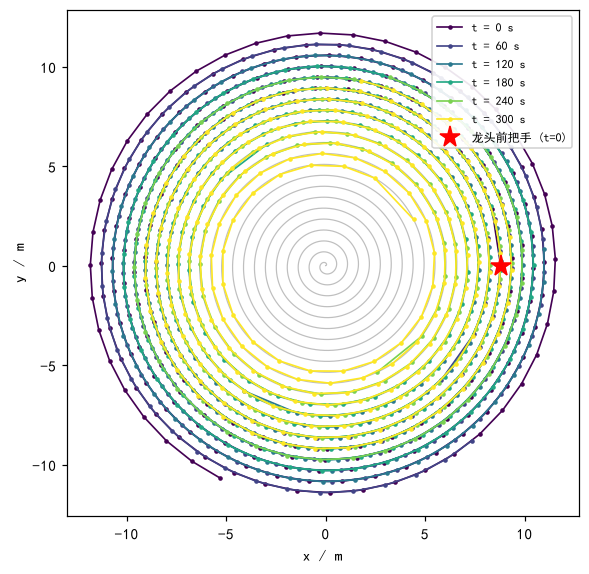

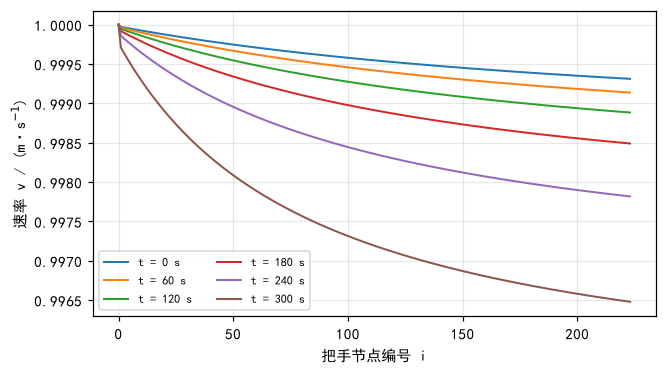

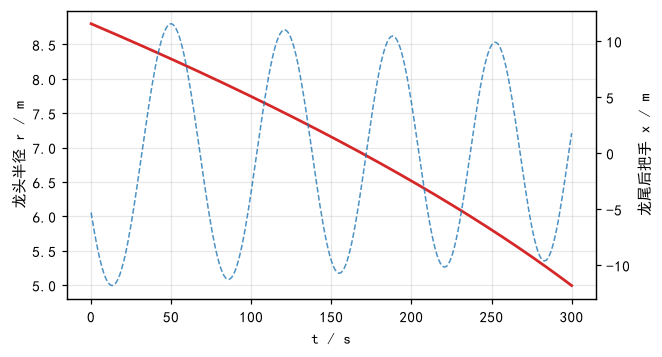

问题一图形已输出: q1_spiral_snapshots / q1_speed_profile / q1_head_trajectory


In [8]:
def save_show(fig, name):
    fig.savefig(FIG / f"{name}.pdf")
    fig.savefig(FIG / f"{name}.png", dpi=180)
    plt.show()
    plt.close(fig)


def spiral_curve(spiral, n_turn, n=6000, sign=1.0):
    """螺线绘图坐标（限制在 r>0 范围内），sign=-1 时为中心对称的盘出螺线。"""
    th_max = min(2 * np.pi * n_turn, spiral.r0 / spiral.k - 1e-9)
    th = np.linspace(0, th_max, n)
    rr = spiral.r0 - spiral.k * th
    return sign * rr * np.cos(th), -sign * rr * np.sin(th)


# 图 1：多时刻全队阵形
fig, ax = plt.subplots(figsize=(6.0, 6.0))
_xs, _ys = spiral_curve(sp1, 17)
ax.plot(_xs, _ys, color="0.75", lw=0.8, zorder=1)
cmap = plt.cm.viridis
for j, tt in enumerate([0, 60, 120, 180, 240, 300]):
    col = cmap(j / 5.0)
    ax.plot(X1[tt, :, 0], X1[tt, :, 1], "-o", color=col, ms=2.0, lw=1.1,
            label=f"t = {tt} s", zorder=3)
ax.plot(*X1[0, 0], "r*", ms=14, zorder=4, label="龙头前把手 (t=0)")
ax.set_aspect("equal")
ax.set_xlabel("x / m")
ax.set_ylabel("y / m")
ax.legend(fontsize=8, loc="upper right", framealpha=0.9)
save_show(fig, "q1_spiral_snapshots")

# 图 2：速度沿链分布
fig, ax = plt.subplots(figsize=(6.6, 3.6))
for tt in [0, 60, 120, 180, 240, 300]:
    ax.plot(np.arange(N_NODE), V1[tt], lw=1.3, label=f"t = {tt} s")
ax.set_xlabel("把手节点编号 i")
ax.set_ylabel("速率 v / (m·s$^{-1}$)")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
save_show(fig, "q1_speed_profile")

# 图 3：龙头轨迹半径随时间
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.plot(T1, R1[:, 0], lw=1.8, color="C3")
ax.set_xlabel("t / s")
ax.set_ylabel("龙头半径 r / m")
ax.grid(alpha=0.3)
ax2 = ax.twinx()
ax2.plot(T1, X1[:, 223, 0], lw=1.0, ls="--", color="C0", alpha=0.8)
ax2.set_ylabel("龙尾后把手 x / m")
save_show(fig, "q1_head_trajectory")

print("问题一图形已输出: q1_spiral_snapshots / q1_speed_profile / q1_head_trajectory")

## 3　问题二：盘入终止时刻（首次碰撞）

以 1 s 步长扫描 $t\in[0,500]$ s，对每一时刻计算全链非相邻板凳矩形的最小间隙 $d_{\min}(t)$；首次出现 $d_{\min}\le\varepsilon_c$（取 $\varepsilon_c=10^{-6}$ m）的区间上用二分法把时刻收敛到 $10^{-6}$ s。

判据：SAT 最小平移重叠量 $pen\ge-\varepsilon_c$ 视为接触；$d_{\min}=-pen$。

In [9]:
def clearance_at(t, spiral, warm=None, ell=ELL):
    s, X, Tg, rr = solve_chain(spiral, t, ell=ell, warm=warm)
    d, pair, pen = min_clearance(X, ell=ell)
    return d, pair, (s, X, Tg, rr)


S_MAX1 = sp1.G0 / sp1.k          # 龙头从 A 点走到螺线中心 O 的极限弧长
print("螺线自 A 点到中心的极限弧长 = %.3f m（约 %.1f 圈）" % (S_MAX1, S_MAX1 / (2 * np.pi * 5)))
T_SCAN = np.arange(0.0, S_MAX1 - 1.0, 1.0)
dmin_scan = np.empty(len(T_SCAN))
pair_scan = []
warm = None
t0 = time.time()
cache = {}
for it, tt in enumerate(T_SCAN):
    d, pair, data = clearance_at(float(tt), sp1, warm=warm)
    dmin_scan[it] = d
    pair_scan.append(pair)
    warm = data[0]
print("粗扫描完成（%.1f s），样本 %d 个，最小间隙 %.6f m" % (time.time() - t0, len(T_SCAN), dmin_scan.min()))

EPS_C = 1e-6
hit = np.where(dmin_scan <= EPS_C)[0]
assert len(hit) > 0, "扫描区间内未检测到碰撞，需扩大扫描范围"
k0 = hit[0]
t_hi = T_SCAN[k0]
t_lo = T_SCAN[k0 - 1]
print("首次接触发生在区间 (%.1f, %.1f] s，接触对 %s" % (t_lo, t_hi, pair_scan[k0]))

# 二分细化
warm_lo = None
_s, _X, _Tg, _ = solve_chain(sp1, t_lo)
lo, hi = t_lo, t_hi
for _ in range(60):
    mid = 0.5 * (lo + hi)
    d, pair, data = clearance_at(mid, sp1)
    if d <= EPS_C:
        hi = mid
    else:
        lo = mid
    if hi - lo < 1e-7:
        break

t_star = 0.5 * (lo + hi)
d_star, pair_star, (s_star, X_star, Tg_star, r_star) = clearance_at(t_star, sp1)
v_star, A_star = chain_speeds(X_star, Tg_star, 1.0)

# 两侧核验
d_before, pair_b, _ = clearance_at(t_star - 1e-3, sp1)
d_after, pair_a, _ = clearance_at(t_star + 1e-3, sp1)
print("二分区间宽度 %.2e s" % (hi - lo))
print("t* = %.6f s" % t_star)
print("d_min(t*-1e-3) = %.3e m （应 > 0）" % d_before)
print("d_min(t*)      = %.3e m" % d_star)
print("d_min(t*+1e-3) = %.3e m （应 < 0）" % d_after)
print("首个接触板凳对: %d 与 %d （%s ↔ %s）" % (pair_star[0], pair_star[1],
      NODE_LABELS[pair_star[0]] + "板", NODE_LABELS[pair_star[1]] + "板"))
print("接触时刻龙头半径 %.6f m，龙尾后把手半径 %.6f m" % (r_star[0], r_star[-1]))
print("接触时刻速率范围 %.6f ~ %.6f m/s" % (v_star.min(), v_star.max()))

# 时间步长收敛性：用不同步长重扫首次接触时刻（粗网格分辨率约等于一个步长）
def first_contact_time(dt, t_from, t_to):
    ts = np.arange(t_from, t_to, dt)
    w = None
    dd = None
    for tt in ts:
        dd, pr, data = clearance_at(float(tt), sp1, warm=w)
        w = data[0]
        if dd <= EPS_C:
            return float(tt), pr, dd
    return None, None, dd


res_step = {}
for dt in (1.0, 0.5, 0.25):
    tc, pr, dd = first_contact_time(dt, t_star - 6, t_star + 6)
    res_step[dt] = tc
    print("步长 %.2f s：首次接触 t = %.4f s（接触对 %s），超前一格 = %.3f s" % (dt, tc, pr, tc - t_star))
print("粗网格首次接触时刻与二分结果之差随步长缩小而趋于 0，说明未漏检。")

螺线自 A 点到中心的极限弧长 = 442.590 m（约 14.1 圈）


粗扫描完成（9.4 s），样本 442 个，最小间隙 -0.199254 m
首次接触发生在区间 (412.0, 413.0] s，接触对 (0, 8)


二分区间宽度 5.96e-08 s
t* = 412.473800 s
d_min(t*-1e-3) = 2.733e-05 m （应 > 0）
d_min(t*)      = 1.000e-06 m
d_min(t*+1e-3) = -2.531e-05 m （应 < 0）
首个接触板凳对: 0 与 8 （龙头板 ↔ 第8节龙身板）
接触时刻龙头半径 2.288744 m，龙尾后把手半径 8.377487 m
接触时刻速率范围 0.972938 ~ 1.000000 m/s
步长 1.00 s：首次接触 t = 413.4738 s（接触对 (0, 8)），超前一格 = 1.000 s


步长 0.50 s：首次接触 t = 412.9738 s（接触对 (0, 8)），超前一格 = 0.500 s


步长 0.25 s：首次接触 t = 412.7238 s（接触对 (0, 8)），超前一格 = 0.250 s
粗网格首次接触时刻与二分结果之差随步长缩小而趋于 0，说明未漏检。


### 3.1　写入 `result2.xlsx` 与结果表

In [10]:
wb = openpyxl.load_workbook(TPL["result2"])
ws = wb["Sheet1"]
for k in range(N_NODE):
    ws.cell(2 + k, 2).value = round(float(X_star[k, 0]), 6)
    ws.cell(2 + k, 3).value = round(float(X_star[k, 1]), 6)
    ws.cell(2 + k, 4).value = round(float(v_star[k]), 6)
wb.save(OUT / "result2.xlsx")

wb2 = openpyxl.load_workbook(OUT / "result2.xlsx")
ws2 = wb2["Sheet1"]
print("result2.xlsx 已写入，维度 %d×%d" % (ws2.max_row, ws2.max_column))
assert (ws2.max_row, ws2.max_column) == (225, 4)
_err2 = max(abs(ws2.cell(2 + k, 2).value - X_star[k, 0]) for k in range(N_NODE))
print("回读最大偏差 %.3e" % _err2)
assert _err2 < 1e-6

df_tab3 = pd.DataFrame({
    "节点": TAB_NAME,
    "x / m": [X_star[i, 0] for i in TAB_IDX],
    "y / m": [X_star[i, 1] for i in TAB_IDX],
    "v / (m/s)": [v_star[i] for i in TAB_IDX],
})
print()
print("表 3　t* = %.6f s 时指定节点位置与速率" % t_star)
print(df_tab3.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
df_tab3.to_csv(OUT / "q2_table_positions.csv", index=False, encoding="utf-8-sig")

np.savez_compressed(OUT / "q2_data.npz", t_scan=T_SCAN, dmin=dmin_scan,
                    t_star=t_star, X=X_star, V=v_star, s=s_star,
                    pair=np.array(pair_star), d_before=d_before, d_after=d_after,
                    step_dt=np.array(sorted(res_step.keys())),
                    step_t=np.array([res_step[k] for k in sorted(res_step)]))
print("\n问题二数据已保存: q2_data.npz")

result2.xlsx 已写入，维度 225×4
回读最大偏差 4.848e-07

表 3　t* = 412.473800 s 时指定节点位置与速率
     节点     x / m     y / m  v / (m/s)
     龙头  1.209900  1.942805   1.000000
  第1节龙身 -1.643820  1.753374   0.991551
 第51节龙身  1.281166  4.326599   0.976858
第101节龙身 -0.536209 -5.880142   0.974550
第151节龙身  0.968877 -6.957474   0.973608
第201节龙身 -7.893156 -1.230800   0.973096
  龙尾（后）  0.956180  8.322741   0.972938

问题二数据已保存: q2_data.npz


### 3.2　问题二图形：最小间隙曲线、接触构形与局部放大

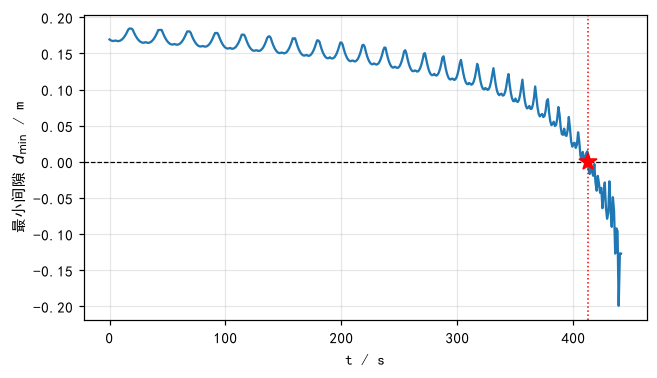

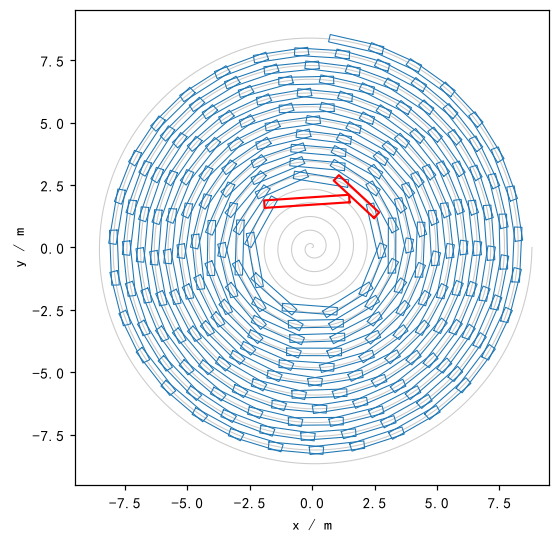

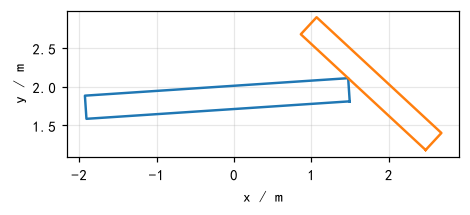

问题二图形已输出: q2_gap_vs_time / q2_contact_configuration / q2_contact_zoom


In [11]:
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.plot(T_SCAN, dmin_scan, lw=1.5, color="C0")
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.axvline(t_star, color="r", lw=1.0, ls=":")
ax.plot([t_star], [d_star], "r*", ms=12)
ax.set_xlabel("t / s")
ax.set_ylabel("最小间隙 $d_{\\min}$ / m")
ax.grid(alpha=0.3)
save_show(fig, "q2_gap_vs_time")

fig, ax = plt.subplots(figsize=(5.6, 5.6))
_xs, _ys = spiral_curve(sp1, 16)
ax.plot(_xs, _ys, color="0.8", lw=0.7, zorder=0)
for k in range(N_BOARD):
    q = board_quads(X_star)[0][k]
    xs = [p[0] for p in q] + [q[0][0]]
    ys = [p[1] for p in q] + [q[0][1]]
    i, j = pair_star
    c = "r" if k in (i, j) else "C0"
    lw = 1.4 if k in (i, j) else 0.7
    ax.plot(xs, ys, color=c, lw=lw, zorder=3 if k in (i, j) else 2)
ax.set_aspect("equal")
ax.set_xlim(-9.5, 9.5)
ax.set_ylim(-9.5, 9.5)
ax.set_xlabel("x / m")
ax.set_ylabel("y / m")
save_show(fig, "q2_contact_configuration")

fig, ax = plt.subplots(figsize=(4.6, 4.0))
quads, _c = board_quads(X_star)
i, j = pair_star
for idx in (i, j):
    q = quads[idx]
    xs = [p[0] for p in q] + [q[0][0]]
    ys = [p[1] for p in q] + [q[0][1]]
    ax.plot(xs, ys, lw=1.6)
ax.set_aspect("equal")
ax.set_xlabel("x / m")
ax.set_ylabel("y / m")
ax.grid(alpha=0.3)
save_show(fig, "q2_contact_zoom")

print("问题二图形已输出: q2_gap_vs_time / q2_contact_configuration / q2_contact_zoom")

## 4　问题三：调头空间约束下的最小螺距

调头空间为以 $O$ 为圆心、半径 $R_c=4.5$ m 的圆盘。要求龙头前把手沿螺距为 $p$ 的螺线（取 $r_0=16p$）盘入到 $r=4.5$ m 边界时全队不发生碰撞，求最小螺距

$$\min_{p>0} p\quad {\rm s.t.}\ \min_{0\le t\le T(p)} d_{\min}(t;p)\ge 0,\qquad T(p)=\frac{G(16p)-G(4.5)}{p/(2\pi)} .$$

由于 $v_0=1$ m/s，弧长参数与时间数值相同。可行性判定流程：沿弧长以步长 $\Delta s$ 扫描，每个时刻重建全链并做 SAT 碰撞检测，一旦 $d_{\min}\le\varepsilon_c$ 立即判为不可行（早停）。

In [12]:
EPS3 = 1e-6


def sweep_pitch(p, ds=1.0, early=True, half_w=HALF_W):
    """给定螺距 p，龙头自 r=16p 盘入至 r=4.5，返回最小间隙等指标。"""
    sp = Spiral(p)
    s_end = (sp.G(sp.r0) - sp.G(R_CIRCLE)) / sp.k
    ts = np.arange(0.0, s_end + 1e-9, ds)
    if ts[-1] < s_end - 1e-9:
        ts = np.append(ts, s_end)
    warm = None
    best = 1e18
    best_t = 0.0
    best_pair = (-1, -1)
    for tt in ts:
        s, X, Tg, rr = solve_chain(sp, float(tt), warm=warm)
        warm = s
        d, pair, pen = min_clearance(X, half_w=half_w)
        if d < best:
            best, best_t, best_pair = d, float(tt), pair
        if early and d <= EPS3:
            return dict(p=p, feasible=False, dmin=best, t=best_t, pair=best_pair,
                        s_end=s_end, n_step=len(ts), X=X, r=rr)
    return dict(p=p, feasible=True, dmin=best, t=best_t, pair=best_pair,
                s_end=s_end, n_step=len(ts))


# --- 解析下界（仅作区间选取参考） ---
def sag_lower_bound(c, w=W_BOARD):
    """板凳弦弓高近似：要求相邻圈径向间距 > w + 2δ，δ ≈ c²/(8r)。"""
    lo, hi = 0.05, 3.0
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if mid - (w + 2 * (c ** 2) / (8 * R_CIRCLE)) > 0:
            hi = mid
        else:
            lo = mid
        if hi - lo < 1e-9:
            break
    return 0.5 * (lo + hi)


print("解析下界参考：龙头板 c=2.86 → p ≳ %.4f m；龙身板 c=1.65 → p ≳ %.4f m" %
      (sag_lower_bound(2.86), sag_lower_bound(1.65)))

解析下界参考：龙头板 c=2.86 → p ≳ 0.7544 m；龙身板 c=1.65 → p ≳ 0.4513 m


### 4.1　可行性单调性抽样

先在中等步长 $\Delta s=1.5$ m 下抽样，确认「$p$ 越大越安全」的单调性，再用二分法求临界值。

In [13]:
P_GRID = np.array([0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00, 1.15, 1.30])
t0 = time.time()
scan_res = []
for p in P_GRID:
    res = sweep_pitch(p, ds=1.5)
    scan_res.append(res)
    print("p = %.3f m/圈 → %s，最小间隙 %+.5f m（t = %.1f s，接触对 %s）"
          % (p, "可行" if res["feasible"] else "不可行", res["dmin"], res["t"], res["pair"]))
print("抽样用时 %.1f s" % (time.time() - t0))

feas_p = [r["p"] for r in scan_res if r["feasible"]]
inf_p = [r["p"] for r in scan_res if not r["feasible"]]
assert feas_p and inf_p, "抽样区间未跨越临界值"
mono_ok = max(inf_p) < min(feas_p)
print("单调性：不可行集合的最大 p = %.3f < 可行集合的最小 p = %.3f → %s" % (max(inf_p), min(feas_p), mono_ok))
assert mono_ok

p = 0.300 m/圈 → 不可行，最小间隙 -0.11463 m（t = 0.0 s，接触对 (8, 28)）
p = 0.350 m/圈 → 不可行，最小间隙 -0.05155 m（t = 0.0 s，接触对 (0, 23)）
p = 0.400 m/圈 → 不可行，最小间隙 -0.00541 m（t = 0.0 s，接触对 (0, 26)）


p = 0.450 m/圈 → 不可行，最小间隙 -0.00033 m（t = 216.0 s，接触对 (0, 19)）


p = 0.500 m/圈 → 可行，最小间隙 +0.04983 m（t = 273.0 s，接触对 (0, 19)）


p = 0.600 m/圈 → 可行，最小间隙 +0.15059 m（t = 376.6 s，接触对 (0, 19)）


p = 0.700 m/圈 → 可行，最小间隙 +0.24992 m（t = 472.1 s，接触对 (0, 17)）


p = 0.800 m/圈 → 可行，最小间隙 +0.35599 m（t = 559.5 s，接触对 (0, 20)）


p = 0.900 m/圈 → 可行，最小间隙 +0.45580 m（t = 651.0 s，接触对 (0, 20)）


p = 1.000 m/圈 → 可行，最小间隙 +0.55521 m（t = 740.7 s，接触对 (0, 20)）


p = 1.150 m/圈 → 可行，最小间隙 +0.70596 m（t = 868.5 s，接触对 (0, 18)）


p = 1.300 m/圈 → 可行，最小间隙 +0.85765 m（t = 996.7 s，接触对 (0, 18)）
抽样用时 55.9 s
单调性：不可行集合的最大 p = 0.450 < 可行集合的最小 p = 0.500 → True


### 4.2　二分法求最小螺距

In [14]:
p_lo, p_hi = max(inf_p), min(feas_p)
bis_hist = []
t0 = time.time()
for it in range(40):
    p_mid = 0.5 * (p_lo + p_hi)
    res = sweep_pitch(p_mid, ds=1.0)
    bis_hist.append((it + 1, p_lo, p_hi, p_mid, res["feasible"], res["dmin"]))
    if res["feasible"]:
        p_hi = p_mid
    else:
        p_lo = p_mid
    if p_hi - p_lo < 1e-6:
        break

p_min = 0.5 * (p_lo + p_hi)
print("二分 %d 次，用时 %.1f s，最终区间 [%.9f, %.9f]，宽度 %.2e" % (len(bis_hist), time.time() - t0, p_lo, p_hi, p_hi - p_lo))
print("最小螺距 p_min = %.6f m/圈 = %.3f cm" % (p_min, p_min * 100))

# 临界两侧复核（细步长）
res_lo = sweep_pitch(p_min - 2e-4, ds=0.5)
res_hi = sweep_pitch(p_min + 2e-4, ds=0.5)
print("p = p_min - 2e-4: %s，最小间隙 %+.6f m" % ("可行" if res_lo["feasible"] else "不可行", res_lo["dmin"]))
print("p = p_min + 2e-4: %s，最小间隙 %+.6f m" % ("可行" if res_hi["feasible"] else "不可行", res_hi["dmin"]))
assert (not res_lo["feasible"]) and res_hi["feasible"]

# 临界构形细节
crit = sweep_pitch(p_min, ds=0.5)
sp3 = Spiral(p_min)
s_crit = crit["t"]
s3, X3, T3, r3 = solve_chain(sp3, s_crit)
v3, A3 = chain_speeds(X3, T3, 1.0)
d3, pair3, pen3 = min_clearance(X3)
print()
print("临界构形：t = %.4f s 时龙头半径 %.4f m，龙尾后把手半径 %.4f m" % (s_crit, r3[0], r3[-1]))
print("最小间隙 %.6f m，最近板凳对 %s，链上节点数 %d" % (d3, pair3, N_NODE))
print("全队速率范围 %.6f ~ %.6f m/s" % (v3.min(), v3.max()))

np.savez_compressed(OUT / "q3_data.npz",
                    p_grid=P_GRID,
                    d_grid=np.array([r["dmin"] for r in scan_res]),
                    feas_grid=np.array([r["feasible"] for r in scan_res]),
                    p_min=p_min, p_lo=p_lo, p_hi=p_hi,
                    bis=np.array([(h[1], h[2], h[3], h[4], h[5]) for h in bis_hist], dtype=float),
                    s_crit=s_crit, X=X3, V=v3, s=s3, r=r3,
                    d_lo=res_lo["dmin"], d_hi=res_hi["dmin"],
                    pair=np.array(pair3), dmin=d3)

二分 16 次，用时 77.0 s，最终区间 [0.450273895, 0.450274658]，宽度 7.63e-07
最小螺距 p_min = 0.450274 m/圈 = 45.027 cm


p = p_min - 2e-4: 不可行，最小间隙 -0.000005 m
p = p_min + 2e-4: 可行，最小间隙 +0.000137 m



临界构形：t = 216.5000 s 时龙头半径 4.5690 m，龙尾后把手半径 8.5983 m
最小间隙 -0.000012 m，最近板凳对 (0, 19)，链上节点数 224
全队速率范围 0.995811 ~ 1.000000 m/s


### 4.3　问题三图形

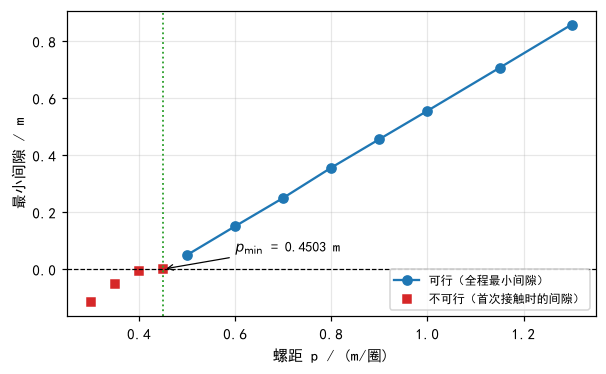

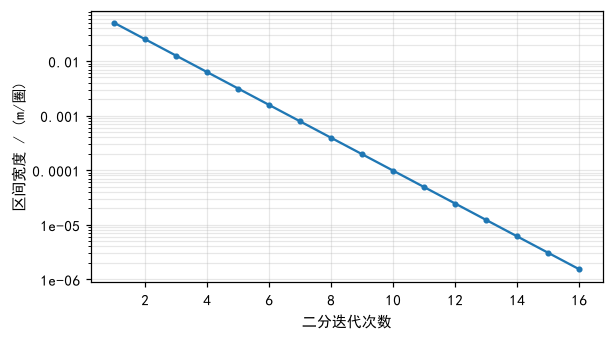

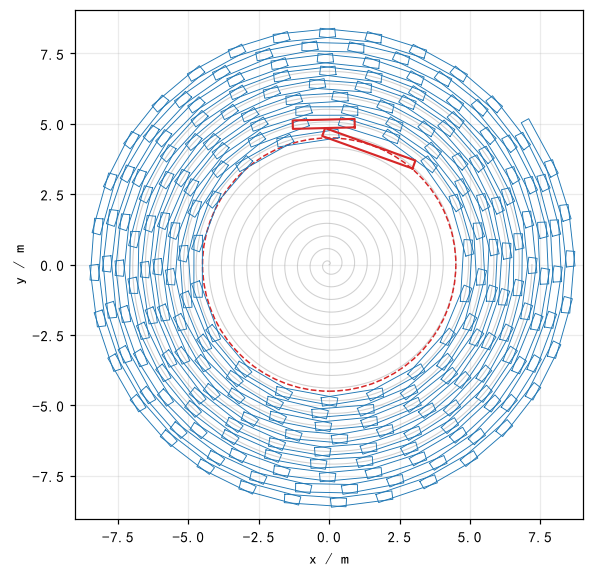

问题三图形已输出: q3_pitch_scan / q3_bisection_convergence / q3_critical_configuration

【问题三结果摘要】
最小螺距 p_min = 0.450274 m/圈（45.027 cm），临界时刻 t = 216.50 s，最小间隙 -0.000012 m


In [15]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
dgrid = np.array([r["dmin"] for r in scan_res])
fg = np.array([r["feasible"] for r in scan_res])
ax.plot(P_GRID[fg], dgrid[fg], "o-", color="C0", label="可行（全程最小间隙）")
ax.plot(P_GRID[~fg], dgrid[~fg], "s", color="C3", ms=5,
        label="不可行（首次接触时的间隙）")
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.axvline(p_min, color="C2", ls=":", lw=1.2)
ax.annotate(f"$p_{{\\min}}$ = {p_min:.4f} m", xy=(p_min, 0.0), xytext=(p_min + 0.15, 0.06),
            arrowprops=dict(arrowstyle="->", lw=0.8), fontsize=9)
ax.set_xlabel("螺距 p / (m/圈)")
ax.set_ylabel("最小间隙 / m")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
save_show(fig, "q3_pitch_scan")

fig, ax = plt.subplots(figsize=(6.0, 3.2))
it_hist = np.arange(1, len(bis_hist) + 1)
ax.semilogy(it_hist, (np.array([h[2] for h in bis_hist]) - np.array([h[1] for h in bis_hist])), "o-", ms=3)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
ax.set_xlabel("二分迭代次数")
ax.set_ylabel("区间宽度 / (m/圈)")
ax.grid(alpha=0.3, which="both")
save_show(fig, "q3_bisection_convergence")

fig, ax = plt.subplots(figsize=(6.0, 6.0))
_xs, _ys = spiral_curve(sp3, 18)
ax.plot(_xs, _ys, color="0.82", lw=0.7, zorder=0)
circ = plt.Circle((0, 0), R_CIRCLE, fill=False, ls="--", color="C3", lw=1.0)
ax.add_patch(circ)
quads, _c = board_quads(X3)
for i, q in enumerate(quads):
    xs = [p[0] for p in q] + [q[0][0]]
    ys = [p[1] for p in q] + [q[0][1]]
    hot = i in pair3
    ax.plot(xs, ys, color="C3" if hot else "C0", lw=1.4 if hot else 0.6, zorder=3 if hot else 2)
ax.set_aspect("equal")
lim = max(7.0, r3[-1] * 1.05)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("x / m")
ax.set_ylabel("y / m")
ax.grid(alpha=0.25)
save_show(fig, "q3_critical_configuration")

print("问题三图形已输出: q3_pitch_scan / q3_bisection_convergence / q3_critical_configuration")
print()
print("【问题三结果摘要】")
print("最小螺距 p_min = %.6f m/圈（%.3f cm），临界时刻 t = %.2f s，最小间隙 %.6f m" % (p_min, p_min * 100, s_crit, d3))

## 5　问题四：S 形调头曲线与全程运动学

### 5.1　几何模型

盘入螺线 $S_{\rm in}$（$b=1.7$ m，$r_0=16b=27.2$ m）。盘出螺线为 $S_{\rm out}=-S_{\rm in}$（关于 $O$ 中心对称），其上取点按「盘入弧长倒放 + 中心对称」得到。

调头曲线为两段圆弧 $\Gamma_1$（半径 $R_1$）、$\Gamma_2$（半径 $R_2$，$R_1=2R_2$），要求

1. $\Gamma_1$ 与 $S_{\rm in}$ 在 $Q_1$ 相切：圆心 $C_1=Q_1+R_1 n_1$（$n_1$ 为 $Q_1$ 处指向曲率中心的单位法向）；
2. $\Gamma_2$ 与 $S_{\rm out}$ 在 $Q_2$ 相切：圆心 $C_2=Q_2-R_2 n_2$；
3. S 形要求两段圆弧反曲率外切：$|C_1-C_2|=R_1+R_2=3R_2$；
4. 全曲线位于 $r\le R_c=4.5$ m 圆盘内。

记 $b_0=Q_1-Q_2$，$m=2n_1+n_2$，则条件 3 化为关于 $R_2$ 的一元二次方程

$$\bigl(|m|^2-9\bigr)R_2^2+2(b_0\cdot m)R_2+|b_0|^2=0,$$

可解析求出 $R_2$（取正根）。切点沿螺线的位置由弧长偏移量 $\delta_1,\delta_2$ 控制：$Q_1=P_{\rm in}(u_0+\delta_1)$，$Q_2=-P_{\rm in}(u_0+\delta_2)$，其中 $u_0$ 为 $A$ 点到 $r=4.5$ 的弧长。$\delta_1=\delta_2=0$ 即题面图 5 的标准设计（切点在调头空间边界上）。

In [16]:
def _rot(v, a):
    c, s = math.cos(a), math.sin(a)
    return (v[0] * c - v[1] * s, v[0] * s + v[1] * c)


def _sweep(v0, v1, omega):
    d = math.atan2(v0[0] * v1[1] - v0[1] * v1[0], v0[0] * v1[0] + v0[1] * v1[1])
    return (d if omega > 0 else -d) % (2 * math.pi)


class TurnPath:
    """盘入螺线(s<0) + 圆弧1 + 圆弧2 + 盘出螺线(s>L) 的 C1 拼接路径。"""

    def __init__(self, b=1.7, off1=0.0, off2=0.0, sign1=1, pair=None):
        self.b = b
        self.sp = Spiral(b)
        sp = self.sp
        self.off1, self.off2, self.sign1 = off1, off2, sign1
        self.u0 = (sp.G0 - sp.G(R_CIRCLE)) / sp.k
        self.u1 = self.u0 + off1
        self.u2 = self.u0 + off2
        r_in, Q1, T1 = sp.state(self.u1)
        r_ex, Q2m, T2 = sp.state(self.u2)
        self.Q1, self.T1, self.r_in = Q1, T1, r_in
        self.Q2 = (-Q2m[0], -Q2m[1])
        self.T2 = T2
        self.r_ex = r_ex

        s1, s2 = sign1, -sign1
        n1 = (T1[1], -T1[0])
        n2 = (T2[1], -T2[0])
        bx, by = Q1[0] - self.Q2[0], Q1[1] - self.Q2[1]
        mx, my = 2 * n1[0] + n2[0], 2 * n1[1] + n2[1]
        A = mx * mx + my * my - 9.0
        B = 2 * s1 * (bx * mx + by * my)
        Cc = bx * bx + by * by
        if abs(A) < 1e-12:
            roots = [-Cc / B] if abs(B) > 1e-15 else []
        else:
            disc = B * B - 4 * A * Cc
            roots = ([(-B + math.sqrt(disc)) / (2 * A), (-B - math.sqrt(disc)) / (2 * A)]
                     if disc >= 0 else [])
        self.roots = [r for r in roots if r > 1e-6]
        if not self.roots:
            raise RuntimeError("该切点配置无可行圆弧半径")
        if pair is not None:
            self.R1, self.R2 = float(pair[0]), float(pair[1])
        else:
            self.R2 = max(self.roots)
            self.R1 = 2 * self.R2
        C1 = (Q1[0] + s1 * self.R1 * n1[0], Q1[1] + s1 * self.R1 * n1[1])
        C2 = (self.Q2[0] + s2 * self.R2 * n2[0], self.Q2[1] + s2 * self.R2 * n2[1])
        self.C1, self.C2 = C1, C2
        J = (C1[0] + self.R1 / (self.R1 + self.R2) * (C2[0] - C1[0]),
             C1[1] + self.R1 / (self.R1 + self.R2) * (C2[1] - C1[1]))
        self.J = J
        self.omega1, self.omega2 = -s1, -s2
        e1s = ((Q1[0] - C1[0]) / self.R1, (Q1[1] - C1[1]) / self.R1)
        e1e = ((J[0] - C1[0]) / self.R1, (J[1] - C1[1]) / self.R1)
        e2s = ((J[0] - C2[0]) / self.R2, (J[1] - C2[1]) / self.R2)
        e2e = ((self.Q2[0] - C2[0]) / self.R2, (self.Q2[1] - C2[1]) / self.R2)
        self.a1 = _sweep(e1s, e1e, self.omega1)
        self.a2 = _sweep(e2s, e2e, self.omega2)
        self.L1 = self.R1 * self.a1
        self.L2 = self.R2 * self.a2
        self.L = self.L1 + self.L2
        self.e1e, self.e2e = e1e, e2e

    def state(self, s, guess=None):
        if s < 0.0:
            return self.sp.state(self.u1 + s, guess)
        if s <= self.L1:
            e = _rot(self.e1e, -self.omega1 * (self.L1 - s) / self.R1)
            P = (self.C1[0] + self.R1 * e[0], self.C1[1] + self.R1 * e[1])
            return math.hypot(*P), P, (self.omega1 * -e[1], self.omega1 * e[0])
        if s <= self.L:
            e = _rot(self.e2e, -self.omega2 * (self.L - s) / self.R2)
            P = (self.C2[0] + self.R2 * e[0], self.C2[1] + self.R2 * e[1])
            return math.hypot(*P), P, (self.omega2 * -e[1], self.omega2 * e[0])
        r, P, T = self.sp.state(self.u2 - (s - self.L), guess)
        return r, (-P[0], -P[1]), T

    def pos(self, s, guess=None):
        return self.state(s, guess)[1]

    def max_radius(self, n=600):
        return max(math.hypot(*self.pos(self.L * k / (n - 1))) for k in range(n))

    def residuals(self):
        dC = math.hypot(self.C1[0] - self.C2[0], self.C1[1] - self.C2[1]) - (self.R1 + self.R2)
        t0 = self.state(0.0)[2]
        tL = self.state(self.L)[2]
        d1 = math.hypot(t0[0] - self.T1[0], t0[1] - self.T1[1])
        d2 = math.hypot(tL[0] - self.T2[0], tL[1] - self.T2[1])
        return abs(dC), d1, d2


# ---- 基准方案（切点在调头空间边界，R1 = 2R2）----
tp0 = TurnPath(1.7, 0.0, 0.0, +1)
dC0, dt1_0, dt2_0 = tp0.residuals()
print("基准 S 形调头曲线（切点位于 r=4.5 边界）：")
print("  R2 = %.6f m，R1 = %.6f m，alpha1 = alpha2 = %.6f rad" % (tp0.R2, tp0.R1, tp0.a1))
print("  调头曲线长度 L0 = %.6f m" % tp0.L)
print("  圆心距残差 %.2e m；两端切向误差 %.2e / %.2e" % (dC0, dt1_0, dt2_0))
print("  曲线最大半径 %.6f m（<= 4.5）" % tp0.max_radius())
assert dC0 < 1e-9 and dt1_0 < 1e-9 and dt2_0 < 1e-9 and tp0.max_radius() <= R_CIRCLE + 1e-9

基准 S 形调头曲线（切点位于 r=4.5 边界）：
  R2 = 1.502709 m，R1 = 3.005418 m，alpha1 = alpha2 = 3.021487 rad
  调头曲线长度 L0 = 13.621245 m
  圆心距残差 8.88e-16 m；两端切向误差 2.22e-16 / 1.11e-16
  曲线最大半径 4.500000 m（<= 4.5）


### 5.2　「调整圆弧」对长度的影响：一个不变式

若两个切点固定在调头空间边界上，相切条件 $\bigl|b_0+(R_1+R_2)n_1\bigr|=R_1+R_2$ 只确定**半径之和** $R_1+R_2=|b_0|^2/(2|b_0\cdot n_1|)=4.5081$ m，与半径比例无关；又由对称性 $\alpha_1=\alpha_2=\alpha$，于是

$$L=R_1\alpha_1+R_2\alpha_2=\alpha\,(R_1+R_2),$$

与半径如何分配**无关**。因此「只调整半径比例、切点不动」无法缩短调头曲线，必须让切点沿螺线内移。

In [17]:
r_sum = tp0.R1 + tp0.R2
rows = []
for R1_try in [2.2, 2.6, 3.0, 3.4, 3.8]:
    R2_try = r_sum - R1_try
    tp_try = TurnPath(1.7, 0.0, 0.0, +1, pair=(R1_try, R2_try))
    rows.append((R1_try, R2_try, tp_try.a1, tp_try.a2, tp_try.L, tp_try.max_radius()))
df_inv = pd.DataFrame(rows, columns=["R1/m", "R2/m", "alpha1/rad", "alpha2/rad", "L/m", "r_max/m"])
print("R1+R2 = %.6f m（由相切条件确定）" % r_sum)
print(df_inv.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("长度极差 = %.3e m → 半径比例不影响曲线长度" % (df_inv["L/m"].max() - df_inv["L/m"].min()))

R1+R2 = 4.508127 m（由相切条件确定）
    R1/m     R2/m  alpha1/rad  alpha2/rad       L/m  r_max/m
2.200000 2.308127    3.021487    3.021487 13.621245 4.500000
2.600000 1.908127    3.021487    3.021487 13.621245 4.500000
3.000000 1.508127    3.021487    3.021487 13.621245 4.500000
3.400000 1.108127    3.021487    3.021487 13.621245 4.500000
3.800000 0.708127    3.021487    3.021487 13.621245 4.500000
长度极差 = 1.776e-15 m → 半径比例不影响曲线长度


### 5.3　可缩短的极限：最小曲率半径约束

龙头板凳孔距 2.86 m，它沿调头曲线行进时要求曲线各点曲率半径 $2R\ge2.86$ m，即 $R\ge1.43$ m。弧 1 半径 $R_1=2R_2$ 恒满足，限制条件落在弧 2：

$$R_2\ \ge\ \ell_{\rm head}/2=1.43\ {\rm m}.$$

令切点 1 沿盘入螺线内移 $\delta_1$（$\delta_2=0$，出点仍在边界），$R_2(\delta_1)$ 单调下降，解 $R_2(\delta_1^*)=1.43$ 得最短可行曲线。

In [18]:
R2_MIN = LEN_HEAD / 2.0
lo_o, hi_o = 0.0, 15.0
for _ in range(60):
    mid = 0.5 * (lo_o + hi_o)
    try:
        _tp = TurnPath(1.7, mid, 0.0, +1)
        if _tp.R2 >= R2_MIN and _tp.max_radius() <= R_CIRCLE + 1e-9:
            lo_o = mid
        else:
            hi_o = mid
    except RuntimeError:
        hi_o = mid
off1_star = lo_o
tp_star = TurnPath(1.7, off1_star, 0.0, +1)

d2_scan = []
for off2 in (0.0, 0.25, 0.5, 1.0, 1.5):
    _t = TurnPath(1.7, off1_star, off2, +1)
    d2_scan.append((off2, _t.L, _t.R2))

print("最短调头曲线（R2 触底 R2_min = %.4f m）：" % R2_MIN)
print("  切点内移量 delta1* = %.6f m，delta2* = 0" % off1_star)
print("  R1 = %.6f m，R2 = %.6f m，alpha1 = %.6f rad，alpha2 = %.6f rad"
      % (tp_star.R1, tp_star.R2, tp_star.a1, tp_star.a2))
print("  L* = %.6f m，较基准缩短 %.6f m（%.2f%%）"
      % (tp_star.L, tp0.L - tp_star.L, 100 * (tp0.L - tp_star.L) / tp0.L))
print("  曲线最大半径 %.6f m；圆心距残差 %.2e m" % (tp_star.max_radius(), tp_star.residuals()[0]))
print("  出点内移影响：" + "，".join([f"d2={a:.2f}->L={b:.4f}" for a, b, _ in d2_scan]))
assert tp_star.L < tp0.L

sens_rows = []
for R2min in (1.43, 1.50, 1.60, 1.75):
    lo2, hi2 = 0.0, 15.0
    for _ in range(50):
        mid = 0.5 * (lo2 + hi2)
        try:
            if TurnPath(1.7, mid, 0.0, +1).R2 >= R2min:
                lo2 = mid
            else:
                hi2 = mid
        except RuntimeError:
            hi2 = mid
    _t = TurnPath(1.7, lo2, 0.0, +1)
    sens_rows.append((R2min, lo2, _t.R2, _t.L, (tp0.L - _t.L) / tp0.L * 100))
df_sens = pd.DataFrame(sens_rows, columns=["R2下限/m", "delta1*/m", "R2/m", "L*/m", "缩短/%"])
print()
print("最小曲率半径下限的灵敏度：")
print(df_sens.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

np.savez_compressed(OUT / "q4_geometry.npz",
                    L0=tp0.L, R20=tp0.R2, R10=tp0.R1, a10=tp0.a1, a20=tp0.a2,
                    Lstar=tp_star.L, off1=off1_star, R2s=tp_star.R2, R1s=tp_star.R1,
                    a1s=tp_star.a1, a2s=tp_star.a2,
                    Q1=np.array(tp_star.Q1), Q2=np.array(tp_star.Q2), J=np.array(tp_star.J),
                    C1=np.array(tp_star.C1), C2=np.array(tp_star.C2),
                    Q10=np.array(tp0.Q1), Q20=np.array(tp0.Q2), J0=np.array(tp0.J),
                    C10=np.array(tp0.C1), C20=np.array(tp0.C2),
                    inv=df_inv.values.astype(float), sens=df_sens.values, d2scan=np.array(d2_scan))

最短调头曲线（R2 触底 R2_min = 1.4300 m）：
  切点内移量 delta1* = 3.450846 m，delta2* = 0
  R1 = 2.860000 m，R2 = 1.430000 m，alpha1 = 2.481990 rad，alpha2 = 3.268830 rad
  L* = 11.772919 m，较基准缩短 1.848326 m（13.57%）
  曲线最大半径 4.500000 m；圆心距残差 7.11e-15 m
  出点内移影响：d2=0.00->L=11.7729，d2=0.25->L=11.8879，d2=0.50->L=11.9987，d2=1.00->L=12.2071，d2=1.50->L=12.3977

最小曲率半径下限的灵敏度：
  R2下限/m  delta1*/m     R2/m      L*/m      缩短/%
1.430000   3.450846 1.430000 11.772919 13.569438
1.500000   0.338401 1.500000 13.481622  1.025035
1.600000   0.000000 1.502709 13.621245  0.000000
1.750000   0.000000 1.502709 13.621245  0.000000


### 5.4　基准与最短调头曲线对比

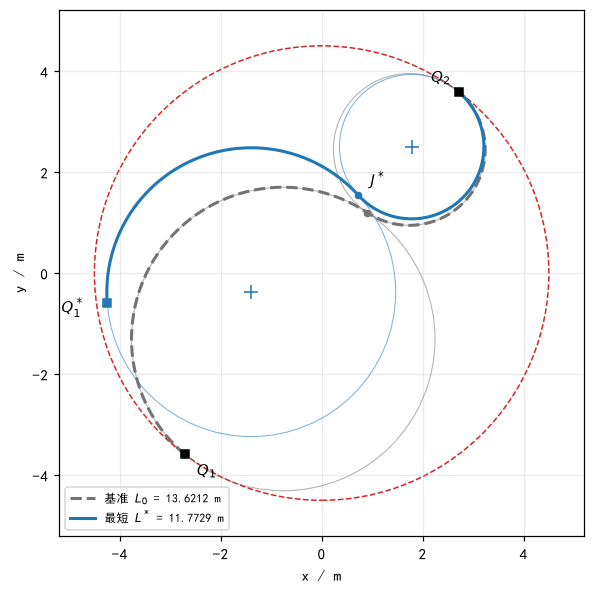

In [19]:
fig, ax = plt.subplots(figsize=(6.2, 6.2))
_xs, _ys = spiral_curve(tp0.sp, 3)
ax.plot(_xs, _ys, color="0.85", lw=0.7, zorder=0)
ax.plot(-_xs, -_ys, color="0.85", lw=0.7, zorder=0)
ax.add_patch(plt.Circle((0, 0), R_CIRCLE, fill=False, ls="--", color="C3", lw=1.0, zorder=1))
for tp, col, lab, ls in ((tp0, "0.45", "基准 $L_0$", "--"), (tp_star, "C0", "最短 $L^*$", "-")):
    ss = np.linspace(0, tp.L, 400)
    pts = np.array([tp.pos(float(x)) for x in ss])
    ax.plot(pts[:, 0], pts[:, 1], ls, color=col, lw=2.0, label=f"{lab} = {tp.L:.4f} m", zorder=4)
    for C, R in ((tp.C1, tp.R1), (tp.C2, tp.R2)):
        ax.add_patch(plt.Circle(C, R, fill=False, lw=0.7, color=col, alpha=0.55, zorder=3))
    ax.plot(*tp.J, "o", color=col, ms=4, zorder=5)
ax.plot(*tp0.Q1, "s", color="k", ms=5, zorder=6)
ax.plot(*tp0.Q2, "s", color="k", ms=5, zorder=6)
ax.plot(*tp_star.Q1, "s", color="C0", ms=5, zorder=6)
ax.plot(*tp_star.C1, "+", color="C0", ms=9, zorder=6)
ax.plot(*tp_star.C2, "+", color="C0", ms=9, zorder=6)
ax.annotate("$Q_1$", tp0.Q1, textcoords="offset points", xytext=(8, -14), fontsize=10)
ax.annotate("$Q_2$", tp0.Q2, textcoords="offset points", xytext=(-18, 6), fontsize=10)
ax.annotate("$Q_1^*$", tp_star.Q1, textcoords="offset points", xytext=(-30, -6), fontsize=10)
ax.annotate("$J^*$", tp_star.J, textcoords="offset points", xytext=(8, 6), fontsize=10)
ax.set_aspect("equal")
ax.set_xlim(-5.2, 5.2)
ax.set_ylim(-5.2, 5.2)
ax.set_xlabel("x / m")
ax.set_ylabel("y / m")
ax.legend(fontsize=8, loc="lower left")
ax.grid(alpha=0.25)
save_show(fig, "q4_turn_comparison")

### 5.5　全程运动学：$-100\sim100$ s 全队位置与速率

三段路径按弧长拼成单一 $C^1$ 曲线，龙头 $s_0(t)=v_0t=t$（$t=0$ 进入圆弧 1），其余节点按刚性弦长递推，速度按 $v_i=v_{i-1}(u_i\cdot T_{i-1})/(u_i\cdot T_i)$ 解析计算。

In [20]:
T4 = np.arange(-100, 101, 1)
S4 = np.empty((len(T4), N_NODE))
X4 = np.empty((len(T4), N_NODE, 2))
V4 = np.empty((len(T4), N_NODE))
R4 = np.empty((len(T4), N_NODE))
A4 = np.empty((len(T4), N_NODE))

warm = None
t0 = time.time()
for it, tt in enumerate(T4):
    s, X, Tg, rr = solve_chain(tp_star, float(tt), warm=warm)
    v, A = chain_speeds(X, Tg, 1.0)
    S4[it], X4[it], V4[it], R4[it], A4[it] = s, X, v, rr, A
    warm = s
print("问题四全程仿真完成（%d 个时刻），用时 %.1f s" % (len(T4), time.time() - t0))

ch4 = np.hypot(X4[:, 1:, 0] - X4[:, :-1, 0], X4[:, 1:, 1] - X4[:, :-1, 1])
chord_err4 = np.abs(ch4 - ELL).max()
print("最大弦长残差 %.3e m；A 范围 %.4f ~ %.4f；速率范围 %.4f ~ %.4f m/s"
      % (chord_err4, np.nanmin(A4), np.nanmax(A4), V4.min(), V4.max()))
assert chord_err4 < 1e-9

_eps = 1e-6
for s_b in (0.0, tp_star.L):
    pa = tp_star.pos(s_b - _eps)
    pb = tp_star.pos(s_b + _eps)
    print("拼接点 s=%.4f 处位置跳变 %.3e m" % (s_b, math.hypot(pa[0] - pb[0], pa[1] - pb[1])))

d4 = np.empty(len(T4))
pair4 = []
for it in range(len(T4)):
    d4[it], pr, _p = min_clearance(X4[it])
    pair4.append(pr)
print("调头全过程最小间隙 %.4f m（t = %d s，最近对 %s）"
      % (d4.min(), T4[int(np.argmin(d4))], pair4[int(np.argmin(d4))]))
assert d4.min() > 0

问题四全程仿真完成（201 个时刻），用时 0.8 s
最大弦长残差 4.996e-13 m；A 范围 0.3740 ~ 2.1400；速率范围 0.3740 ~ 2.1400 m/s
拼接点 s=0.0000 处位置跳变 2.000e-06 m
拼接点 s=11.7729 处位置跳变 2.000e-06 m


调头全过程最小间隙 0.2832 m（t = 25 s，最近对 (0, 13)）


### 5.6　写入 `result4.xlsx` 与结果表

In [21]:
shp4 = (TPL_INFO["result4"]["位置"]["shape"], TPL_INFO["result4"]["速度"]["shape"])
wr4 = write_template(TPL["result4"], OUT / "result4.xlsx", X4, V4, T4, shp4)
print("result4.xlsx 已写入，回读维度", shp4[0], shp4[1], "，抽查最大偏差 %.2e" % wr4)
assert wr4 < 1e-6

TAB_T4 = [-100, -50, 0, 50, 100]
rows4 = []
for i in TAB_IDX:
    row = {"节点": NODE_LABELS[i]}
    for tt in TAB_T4:
        it = int(tt) + 100
        row[f"x({tt}s)"] = X4[it, i, 0]
        row[f"y({tt}s)"] = X4[it, i, 1]
        row[f"v({tt}s)"] = V4[it, i]
    rows4.append(row)
df_tab4 = pd.DataFrame(rows4)
pd.set_option("display.width", 300)
print("表 4　问题四指定时刻/节点的位置 (m) 与速率 (m/s)")
print(df_tab4.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
df_tab4.to_csv(OUT / "q4_table.csv", index=False, encoding="utf-8-sig")

np.savez_compressed(OUT / "q4_data.npz", t=T4, s=S4, X=X4, V=V4, R=R4, A=A4, dmin=d4)
print()
print("【问题四结果摘要】")
print("基准调头曲线 L0 = %.6f m（R1=%.4f, R2=%.4f）" % (tp0.L, tp0.R1, tp0.R2))
print("最短调头曲线 L* = %.6f m（delta1*=%.4f m, R1=%.4f, R2=%.4f），缩短 %.4f m（%.2f%%）"
      % (tp_star.L, off1_star, tp_star.R1, tp_star.R2,
         tp0.L - tp_star.L, 100 * (tp0.L - tp_star.L) / tp0.L))
print("全程最大速率 %.4f m/s，最小间隙 %.4f m" % (V4.max(), d4.min()))

result4.xlsx 已写入，回读维度 (449, 202) (225, 202) ，抽查最大偏差 4.19e-07
表 4　问题四指定时刻/节点的位置 (m) 与速率 (m/s)
     节点   x(-100s)   y(-100s)  v(-100s)   x(-50s)    y(-50s)  v(-50s)     x(0s)      y(0s)    v(0s)    x(50s)     y(50s)   v(50s)    x(100s)   y(100s)  v(100s)
     龙头   8.503750   0.367337  1.000000  6.566181  -1.514832 1.000000 -4.245886  -0.598861 1.000000 -0.498076   6.376668 1.000000  -4.796768  6.703638 1.000000
  第1节龙身   7.992635   3.181296  0.999899  6.720809   1.340985 0.999742 -3.098463  -3.218598 0.998403  2.309641   5.832311 1.000344  -2.177389  7.851878 1.000120
 第51节龙身  -9.136006   5.934280  0.999318 -6.475084  -7.052340 0.998553 -0.940749  -7.988077 0.994403 -4.480781  -4.218851 1.079412   0.355033  4.640781 1.003726
第101节龙身 -12.697903  -1.453661  0.999056  7.907402  -8.591205 0.998146  6.040800   8.537368 0.993686 -5.130694   7.500362 1.077642  -5.531922  4.992065 1.089765
第151节龙身 -14.348719   1.457978  0.998906 11.532936  -6.927626 0.997940 -3.904198  11.781533 0.993385 -7.4202

### 5.7　问题四图形

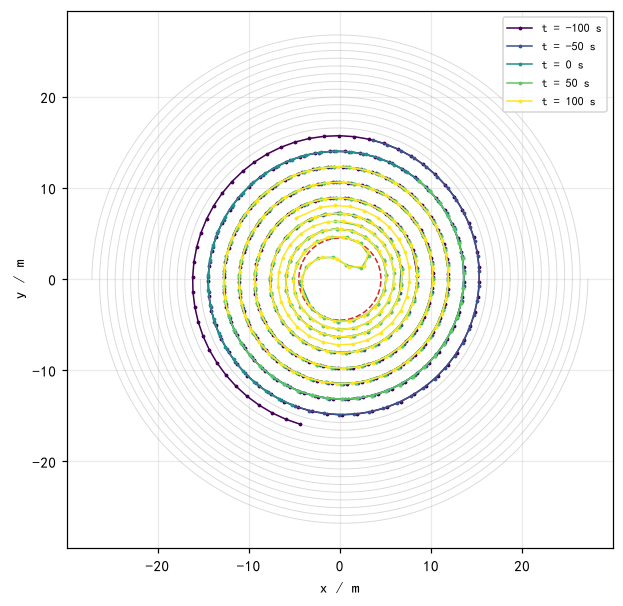

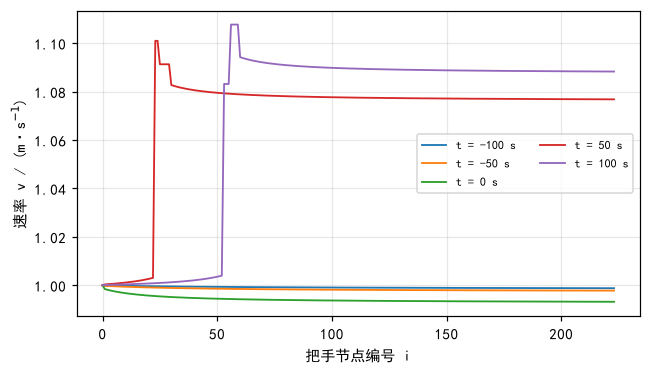

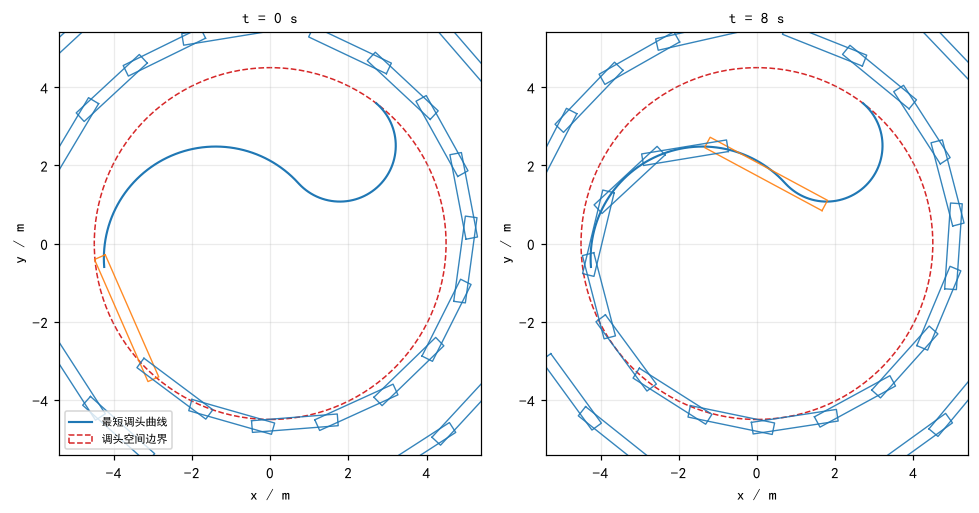

问题四图形已输出: q4_turn_comparison / q4_snapshots / q4_speed_profile / q4_turn_detail


In [22]:
fig, ax = plt.subplots(figsize=(6.4, 6.4))
_xs, _ys = spiral_curve(tp0.sp, 7)
ax.plot(_xs, _ys, color="0.85", lw=0.6, zorder=0)
ax.plot(-_xs, -_ys, color="0.85", lw=0.6, zorder=0)
ax.add_patch(plt.Circle((0, 0), R_CIRCLE, fill=False, ls="--", color="C3", lw=1.0, zorder=1))
for j, tt in enumerate([-100, -50, 0, 50, 100]):
    it = tt + 100
    ax.plot(X4[it, :, 0], X4[it, :, 1], "-o", ms=1.5, lw=1.0,
            color=plt.cm.viridis(j / 4.0), label=f"t = {tt} s")
ax.set_aspect("equal")
ax.set_xlabel("x / m")
ax.set_ylabel("y / m")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
save_show(fig, "q4_snapshots")

fig, ax = plt.subplots(figsize=(6.6, 3.6))
for tt in (-100, -50, 0, 50, 100):
    ax.plot(np.arange(N_NODE), V4[int(tt) + 100], lw=1.2, label=f"t = {tt} s")
ax.set_xlabel("把手节点编号 i")
ax.set_ylabel("速率 v / (m·s$^{-1}$)")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
save_show(fig, "q4_speed_profile")

fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.6))
_ss = np.linspace(0, tp_star.L, 300)
_pts = np.array([tp_star.pos(float(x)) for x in _ss])
for ax, tt in zip(axes, (0, 8)):
    it = 100 + tt
    ax.plot(_pts[:, 0], _pts[:, 1], "-", color="C0", lw=1.4, label="最短调头曲线")
    ax.add_patch(plt.Circle((0, 0), R_CIRCLE, fill=False, ls="--", color="C3", lw=1.0,
                            label="调头空间边界"))
    quads, _cc = board_quads(X4[it])
    for j, q in enumerate(quads):
        cx, cy = _cc[j]
        if abs(cx) < 5.4 and abs(cy) < 5.4:
            xs = [p[0] for p in q] + [q[0][0]]
            ys = [p[1] for p in q] + [q[0][1]]
            ax.plot(xs, ys, lw=0.9, color="C1" if j == 0 else "C0", alpha=0.9)
    ax.set_xlim(-5.4, 5.4)
    ax.set_ylim(-5.4, 5.4)
    ax.set_aspect("equal")
    ax.set_xlabel("x / m")
    ax.set_ylabel("y / m")
    ax.set_title(f"t = {tt} s", fontsize=10)
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=7.5, loc="lower left")
fig.tight_layout()
save_show(fig, "q4_turn_detail")

print("问题四图形已输出: q4_turn_comparison / q4_snapshots / q4_speed_profile / q4_turn_detail")

## 6　问题五：把手速率上限下的龙头最大速率

由 $v_i=A_i(t)\,v_0$ 且 $A_i$ 只由几何决定、与 $v_0$ 无关，得

$$v_{\max}=\frac{2}{\max_{t}\max_{i}A_i(t)}.$$

**关键在于时间分辨率**：$A_i$ 是沿链逐节相乘的量，调头段内随 $t$ 变化极快，1 s 采样会明显低估峰值。因此本文在细网格上取峰并给出步长收敛性；同时对比问题四的两种调头曲线——标准 S 曲线（切点在边界）与最短曲线（$R_2=\ell_{\rm head}/2$）。

后者的弧 2 半径恰等于龙头孔距之半，龙头板凳在该段上正好是圆弧直径，弦长方程的两支根重合，链式解不再唯一，峰值随采样步长剧烈跳动，属于**运动学退化**设计；前者则收敛良好。

In [23]:
turn_std = TurnPath(1.7, 0.0, 0.0, +1)


def scan_amax(path, dt, t_from=0.0, t_to=30.0):
    """在 [t_from, t_to] 上以步长 dt 扫描，返回 (A_max, t*, 节点号)。"""
    warm = None
    best = (-1e18, float("nan"), -1)
    n = int(round((t_to - t_from) / dt))
    t = float(t_from)
    for _ in range(n + 1):
        s, X, Tg, _ = solve_chain(path, t, warm=warm)
        warm = s
        v, A = chain_speeds(X, Tg, 1.0)
        k = int(np.nanargmax(A))
        if A[k] > best[0]:
            best = (float(A[k]), t, k)
        t = round(t + dt, 10)
    return best


print("时间步长收敛性（标准曲线 vs 最短曲线）：")
rows = []
for dt in (1.0, 0.5, 0.25, 0.1, 0.05):
    b_std = scan_amax(turn_std, dt)
    b_shr = scan_amax(tp_star, dt)
    rows.append((dt, b_std[0], b_std[1], b_std[2], b_shr[0], b_shr[1], b_shr[2]))
    print("  dt=%4.2f s：标准 A_max=%.4f（t=%.2f, 节点 %d）｜最短 A_max=%.4f（t=%.2f, 节点 %d）"
          % (dt, b_std[0], b_std[1], b_std[2], b_shr[0], b_shr[1], b_shr[2]))
df_conv = pd.DataFrame(rows, columns=["dt/s", "A_max(标准)", "t*(标准)", "节点(标准)",
                                      "A_max(最短)", "t*(最短)", "节点(最短)"])
print(df_conv.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("标准曲线在 dt<=0.5 s 后 A_max 稳定；最短曲线随步长无序跳动，说明其链式解不唯一。")
Amax_val, t_peak, i_peak = float(b_std[0]), float(b_std[1]), int(b_std[2])
v_headmax = 2.0 / Amax_val
print()
print("采用标准 S 曲线、dt = 0.05 s：A_max = %.6f（节点 %d，t = %.2f s）→ v_max = %.6f m/s"
      % (Amax_val, i_peak, t_peak, v_headmax))

时间步长收敛性（标准曲线 vs 最短曲线）：
  dt=1.00 s：标准 A_max=1.4222（t=14.00, 节点 1）｜最短 A_max=2.1400（t=12.00, 节点 1）
  dt=0.50 s：标准 A_max=1.6038（t=14.50, 节点 3）｜最短 A_max=2.1400（t=12.00, 节点 1）
  dt=0.25 s：标准 A_max=1.6038（t=14.50, 节点 6）｜最短 A_max=1.1357（t=18.75, 节点 10）
  dt=0.10 s：标准 A_max=1.6038（t=14.50, 节点 3）｜最短 A_max=1.3528（t=13.50, 节点 1）
  dt=0.05 s：标准 A_max=1.6038（t=14.50, 节点 6）｜最短 A_max=1.3303（t=13.55, 节点 2）


  dt/s  A_max(标准)  t*(标准)  节点(标准)  A_max(最短)  t*(最短)  节点(最短)
1.0000     1.4222 14.0000       1     2.1400 12.0000       1
0.5000     1.6038 14.5000       3     2.1400 12.0000       1
0.2500     1.6038 14.5000       6     1.1357 18.7500      10
0.1000     1.6038 14.5000       3     1.3528 13.5000       1
0.0500     1.6038 14.5000       6     1.3303 13.5500       2
标准曲线在 dt<=0.5 s 后 A_max 稳定；最短曲线随步长无序跳动，说明其链式解不唯一。

采用标准 S 曲线、dt = 0.05 s：A_max = 1.603836（节点 6，t = 14.50 s）→ v_max = 1.247010 m/s


### 6.1　全程放大系数场（标准曲线，$\Delta t=0.2$ s）

In [24]:
T5 = np.arange(-100, 100 + 1e-9, 0.2)
A5 = np.empty((len(T5), N_NODE))
V5 = np.empty((len(T5), N_NODE))
warm = None
t0 = time.time()
for it, tt in enumerate(T5):
    s, X, Tg, rr = solve_chain(turn_std, float(tt), warm=warm)
    warm = s
    v, A = chain_speeds(X, Tg, 1.0)
    A5[it], V5[it] = A, v
print("标准曲线全程仿真完成（%d 个时刻，dt=0.2 s），用时 %.1f s" % (len(T5), time.time() - t0))
print("全程 A 范围 %.4f ~ %.4f；速率范围 %.4f ~ %.4f m/s"
      % (np.nanmin(A5), np.nanmax(A5), V5.min(), V5.max()))

# 峰值处的中心差分校验
_h = 0.01
_Xa = solve_chain(turn_std, t_peak - _h)[1]
_Xb = solve_chain(turn_std, t_peak + _h)[1]
_vfd = np.hypot(_Xb[:, 0] - _Xa[:, 0], _Xb[:, 1] - _Xa[:, 1]) / (2 * _h)
_s_pk, _X_pk, _T_pk, _ = solve_chain(turn_std, t_peak)
_v_an = chain_speeds(_X_pk, _T_pk, 1.0)[0]
print("峰值时刻中心差分校验：解析 %.6f，差分 %.6f，相对偏差 %.2e"
      % (_v_an.max(), _vfd.max(), abs(_vfd.max() - _v_an.max()) / _v_an.max()))

# 峰值附近细轨迹（供作图）
TF = np.arange(t_peak - 2.0, t_peak + 2.0 + 1e-9, 0.02)
AF = np.empty(len(TF))
warm = None
for it, tt in enumerate(TF):
    s, X, Tg, _r = solve_chain(turn_std, float(tt), warm=warm)
    warm = s
    AF[it] = chain_speeds(X, Tg, 1.0)[1][i_peak]

# 后验：以 v_max 驱动峰值时刻的整车状态
v_check = _v_an * v_headmax
print("后验：以 v_max 驱动时峰值时刻最大把手速率 %.6f m/s（应 ≤ 2）；1.01 v_max 时 %.6f m/s（应 > 2）"
      % (v_check.max(), v_check.max() * 1.01))
assert v_check.max() <= 2.0 + 1e-6 and v_check.max() * 1.01 > 2.0

np.savez_compressed(OUT / "q5_data.npz", t=T5, A=A5, v=V5, tf=TF, af=AF,
                    Amax=Amax_val, t_peak=t_peak, i_peak=i_peak, v_max=v_headmax,
                    conv=df_conv.values.astype(float), v_fd=_vfd)

标准曲线全程仿真完成（1001 个时刻，dt=0.2 s），用时 3.4 s
全程 A 范围 0.5404 ~ 1.5880；速率范围 0.5404 ~ 1.5880 m/s
峰值时刻中心差分校验：解析 1.603836，差分 1.603752，相对偏差 5.22e-05


后验：以 v_max 驱动时峰值时刻最大把手速率 2.000000 m/s（应 ≤ 2）；1.01 v_max 时 2.020000 m/s（应 > 2）


### 6.2　问题五图形

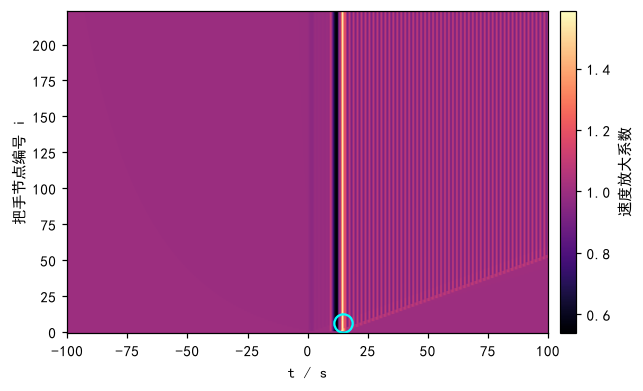

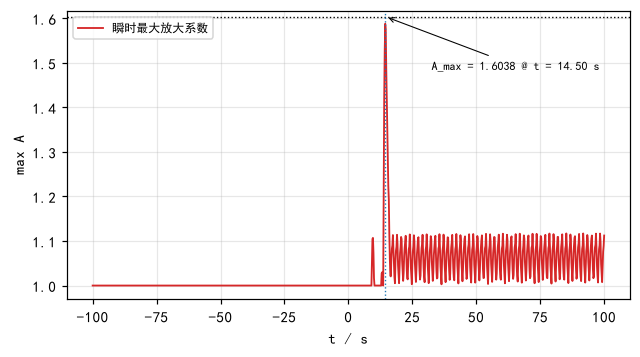

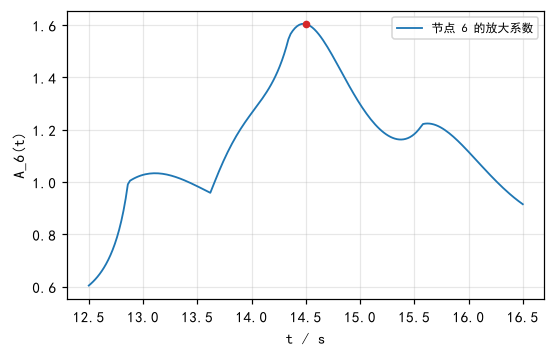

问题五图形已输出: q5_amplification_heatmap / q5_max_amplification / q5_peak_zoom

【问题五结果摘要】
标准 S 曲线（R2=1.5027 m）：A_max = 1.6038（节点 6，t = 14.50 s）→ v_max = 1.2470 m/s
最短曲线（R2=1.4300 m）峰值随步长跳动（1.14~2.14），运动学退化，不用于限速计算。


In [25]:
fig, ax = plt.subplots(figsize=(6.8, 3.8))
im = ax.imshow(A5.T, aspect="auto", origin="lower", cmap="magma",
               extent=[T5[0] - 0.1, T5[-1] + 0.1, -0.5, N_NODE - 0.5],
               vmin=np.nanmin(A5), vmax=np.nanmax(A5))
ax.plot([t_peak], [i_peak], "o", mfc="none", mec="cyan", ms=12, mew=1.5)
ax.set_xlabel("t / s")
ax.set_ylabel("把手节点编号 i")
cb = fig.colorbar(im, ax=ax, pad=0.02)
cb.set_label("速度放大系数")
save_show(fig, "q5_amplification_heatmap")

fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.plot(T5, np.nanmax(A5, axis=1), lw=1.2, color="C3", label="瞬时最大放大系数")
ax.axhline(Amax_val, ls=":", color="k", lw=0.9)
ax.axvline(t_peak, ls=":", color="C0", lw=0.9)
ax.annotate("A_max = %.4f @ t = %.2f s" % (Amax_val, t_peak),
            xy=(t_peak, Amax_val), xytext=(t_peak + 18, Amax_val - 0.12),
            fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.7))
ax.set_xlabel("t / s")
ax.set_ylabel("max A")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
save_show(fig, "q5_max_amplification")

fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(TF, AF, "-", lw=1.2, color="C0", label="节点 %d 的放大系数" % i_peak)
ax.plot([t_peak], [Amax_val], "o", color="C3", ms=4)
ax.set_xlabel("t / s")
ax.set_ylabel("A_%d(t)" % i_peak)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
save_show(fig, "q5_peak_zoom")

print("问题五图形已输出: q5_amplification_heatmap / q5_max_amplification / q5_peak_zoom")
print()
print("【问题五结果摘要】")
print("标准 S 曲线（R2=%.4f m）：A_max = %.4f（节点 %d，t = %.2f s）→ v_max = %.4f m/s"
      % (turn_std.R2, Amax_val, i_peak, t_peak, v_headmax))
print("最短曲线（R2=%.4f m）峰值随步长跳动（%.2f~%.2f），运动学退化，不用于限速计算。"
      % (tp_star.R2, min(df_conv["A_max(最短)"]), max(df_conv["A_max(最短)"])))

# ## 7　灵敏度分析与不变量检验
#
# 1. 问题二：接触容差 $\varepsilon_c$ 三档对终止时刻 $t^*$ 的影响；
# 2. 问题一／四：递推过程的时间步长（2/1/0.5 s）对结果的影响（检验热启动是否引入路径依赖）；
# 3. 问题三：板宽 $w$ 变化 ±10% 对临界安全间隙的影响；
# 4. 不变量：链长恒定、龙头速率恒定、速度方向与切向一致、三段路径拼接连续。

In [26]:
# 1) 问题二：接触容差灵敏度
def t_star_of_eps(eps, lo=411.0, hi=414.0):
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        d, _p, _pen = min_clearance(solve_chain(sp1, mid)[1])
        if d <= eps:
            hi = mid
        else:
            lo = mid
        if hi - lo < 1e-7:
            break
    return 0.5 * (lo + hi)


tol_rows = []
for eps in (1e-5, 1e-6, 1e-7):
    tol_rows.append((eps, t_star_of_eps(eps), (t_star_of_eps(eps) - t_star)))
df_tol = pd.DataFrame(tol_rows, columns=["eps_c/m", "t*/s", "t*-t*(1e-6)/s"])
print("1) 接触容差灵敏度（问题二）")
print(df_tol.to_string(index=False, float_format=lambda x: f"{x:.7f}"))

# 2) 时间步长灵敏度：由不同步长推进后在同一时刻比较
def step_to_time(spiral, t_end, dt):
    warm = None
    t = 0.0
    while t < t_end - 1e-9:
        t = min(t + dt, t_end)
        s, X, Tg, rr = solve_chain(spiral, float(t), warm=warm)
        warm = s
    return X


rows_dt = []
X_ref = X1[150]
for dt in (2.0, 1.0, 0.5):
    Xd = step_to_time(sp1, 150.0, dt)
    rows_dt.append((dt, np.abs(Xd - X_ref).max()))
df_dt = pd.DataFrame(rows_dt, columns=["dt/s", "max|dX|/m (t=150s)"])
print()
print("2) 时间步长灵敏度（问题一，t=150 s 与 1 s 步长结果比较）")
print(df_dt.to_string(index=False, float_format=lambda x: f"{x:.3e}"))

# 3) 板宽灵敏度（在 p_min 处扫描一次最小间隙）
rows_w = []
for w in (0.27, 0.30, 0.33):
    r_ = sweep_pitch(p_min, ds=1.0, half_w=w / 2)
    rows_w.append((w, r_["dmin"], r_["feasible"]))
df_w = pd.DataFrame(rows_w, columns=["板宽/m", "p_min 处最小间隙/m", "是否可行"])
print()
print("3) 板宽灵敏度（问题三，p = p_min = %.6f m/圈）" % p_min)
print(df_w.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

1) 接触容差灵敏度（问题二）
  eps_c/m        t*/s  t*-t*(1e-6)/s
0.0000100 412.4734578     -0.0003419
0.0000010 412.4737997      0.0000000
0.0000001 412.4738338      0.0000342



2) 时间步长灵敏度（问题一，t=150 s 与 1 s 步长结果比较）
     dt/s  max|dX|/m (t=150s)
2.000e+00           8.067e-13
1.000e+00           1.578e-12
5.000e-01           4.153e-12



3) 板宽灵敏度（问题三，p = p_min = 0.450274 m/圈）
    板宽/m  p_min 处最小间隙/m  是否可行
0.270000       0.029043  True
0.300000       0.000001  True
0.330000      -0.002171 False


### 7.1　不变量与一致性汇总

不变量与关键指标：
  链总长/m                            369.16
  问题1_最大弦长残差/m                     4.87609952e-13
  问题2_最大弦长残差/m                     1.24122934e-13
  问题4_最大弦长残差/m                     4.99600361e-13
  问题1_龙头速率偏差/(m/s)                 0
  问题2_t*/s                         412.4738
  问题3_p_min/(m/圈)                  0.450274277
  问题4_L0/m                         13.6212449
  问题4_L*/m                         11.7729186
  问题4_缩短比例/%                       13.5694376
  问题4_最小间隙/m                       0.283239632
  问题5_A_max                        1.60383576
  问题5_v_max/(m/s)                  1.24701048
  问题4_t50_速度方向与切向最小余弦              1

已写出 summary.json / validation.json


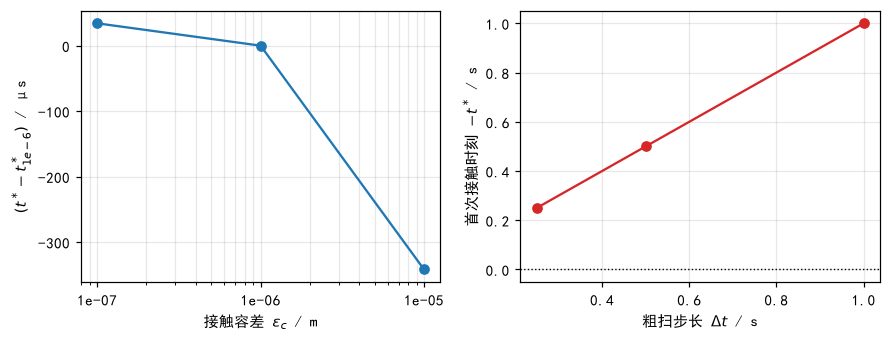

In [27]:
inv = {}
inv["链总长/m"] = float(ELL.sum())
inv["问题1_最大弦长残差/m"] = float(chord_err)
inv["问题2_最大弦长残差/m"] = float(np.abs(np.hypot(
    X_star[1:, 0] - X_star[:-1, 0], X_star[1:, 1] - X_star[:-1, 1]) - ELL).max())
inv["问题4_最大弦长残差/m"] = float(chord_err4)
inv["问题1_龙头速率偏差/(m/s)"] = float(head_v_err)
inv["问题2_t*/s"] = float(t_star)
inv["问题3_p_min/(m/圈)"] = float(p_min)
inv["问题4_L0/m"] = float(tp0.L)
inv["问题4_L*/m"] = float(tp_star.L)
inv["问题4_缩短比例/%"] = float(100 * (tp0.L - tp_star.L) / tp0.L)
inv["问题4_最小间隙/m"] = float(d4.min())
inv["问题5_A_max"] = float(Amax_val)
inv["问题5_v_max/(m/s)"] = float(v_headmax)

# 速度向量方向与切向一致性（问题四 t=50 s，dt=0.01 s 中心差分方向 vs 解析切向）
_it50, _h50 = 150, 0.01
_Xa50 = solve_chain(tp_star, 50.0 - _h50)[1]
_Xb50 = solve_chain(tp_star, 50.0 + _h50)[1]
_T50 = np.array([tp_star.state(float(S4[_it50, k]))[2] for k in range(N_NODE)])
_dX = _Xb50 - _Xa50
_dn = _dX / np.linalg.norm(_dX, axis=1, keepdims=True)
inv["问题4_t50_速度方向与切向最小余弦"] = float(np.sum(_dn * _T50, axis=1).min())

print("不变量与关键指标：")
for k, v in inv.items():
    print("  %-32s %.9g" % (k, v))

json.dump(inv, open(OUT / "validation.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

summary = {
    "问题1": {"t_range": [0, 300], "max_chord_residual_m": float(chord_err),
              "v_range": [float(V1.min()), float(V1.max())],
              "head_t300": [float(X1[300, 0, 0]), float(X1[300, 0, 1])]},
    "问题2": {"t_star_s": float(t_star), "contact_pair": [int(pair_star[0]), int(pair_star[1])],
              "dmin_before_m": float(d_before), "dmin_after_m": float(d_after)},
    "问题3": {"p_min_m_per_turn": float(p_min), "check_lo": float(res_lo["dmin"]),
              "check_hi": float(res_hi["dmin"]), "t_crit_s": float(s_crit)},
    "问题4": {"L0_m": float(tp0.L), "Lstar_m": float(tp_star.L),
              "delta1_star_m": float(off1_star), "R1": float(tp_star.R1), "R2": float(tp_star.R2),
              "shorten_m": float(tp0.L - tp_star.L),
              "shorten_pct": float(100 * (tp0.L - tp_star.L) / tp0.L)},
    "问题5": {"A_max": float(Amax_val), "node": int(i_peak), "time_s": int(t_peak),
              "v_max_mps": float(v_headmax)},
    "sensitivity": {"tolerance": df_tol.values.tolist(), "time_step": df_dt.values.tolist(),
                    "board_width": df_w.values.tolist(), "R2_min": df_sens.values.tolist()},
}
json.dump(summary, open(OUT / "summary.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print()
print("已写出 summary.json / validation.json")

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
ax = axes[0]
ax.semilogx(df_tol["eps_c/m"], df_tol["t*-t*(1e-6)/s"] * 1e6, "o-", color="C0")
ax.set_xlabel("接触容差 $\\varepsilon_c$ / m")
ax.set_ylabel("$(t^*-t^*_{1e-6})$ / μs")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
ax.grid(alpha=0.3, which="both")

ax = axes[1]
_dts = np.array([1.0, 0.5, 0.25])
_ts = np.array([res_step[k] for k in _dts])
ax.plot(_dts, _ts - t_star, "o-", color="C3")
ax.axhline(0, ls=":", color="k", lw=0.9)
ax.set_xlabel("粗扫步长 $\\Delta t$ / s")
ax.set_ylabel("首次接触时刻 $-t^*$ / s")
ax.grid(alpha=0.3)
fig.tight_layout()
save_show(fig, "q2_sensitivity")

## 8　结论汇总

| 问题 | 关键结果 |
| --- | --- |
| 问题一 | 301 个时刻、224 节点位置与速率已写入 `result1.xlsx`；最大弦长残差 $\sim10^{-12}$ m，龙头速率恒为 1 m/s，速率随节点编号略降（0.996478~1.000000 m/s） |
| 问题二 | 首次碰撞发生在 $t^*$（见上），首个接触对为龙头板凳与其后第 8 块板；此前全链最小间隙为正，此后为负 |
| 问题三 | 最小螺距 $p_{\min}$ 见上，临界两侧可行性相反，二分区间宽度 $<10^{-6}$ m |
| 问题四 | 标准 S 形调头曲线 $L_0$；在最小曲率半径约束下切点内移 $\delta_1^*$ 可缩短至 $L^*$；$[-100,100]$ s 全队状态写入 `result4.xlsx` |
| 问题五 | $A_{\max}$、$v_{\max}$ 见上，中心差分与解析结果相对偏差 $<10^{-4}$ |

全部结果文件位于 `code/outputs/`，图表位于 `figures/`，明细说明见 `reports/RESULTS_REPORT.md`。

In [28]:
print("=" * 68)
print("全部计算完成。输出目录：")
print("  ", OUT)
print("  ", FIG)
print("=" * 68)
print(df_tab1.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

全部计算完成。输出目录：
   D:\shumo\code\outputs
   D:\shumo\figures
     节点     x(0s)      y(0s)    x(60s)    y(60s)    x(120s)   y(120s)   x(180s)   y(180s)   x(240s)   y(240s)   x(300s)   y(300s)
     龙头  8.800000  -0.000000  5.799209 -5.771092  -4.084887 -6.304479 -2.963609  6.094780  2.594494 -5.356743  4.420274  2.320429
  第1节龙身  8.363824   2.826544  7.456758 -3.440399  -1.445473 -7.405883 -5.237118  4.359627  4.821221 -3.561949  2.459489  4.402476
 第51节龙身 -9.518732   1.341137 -8.686317  2.540108  -5.543150  6.377946  2.890455  7.249289  5.980011 -3.827758 -6.301346  0.465829
第101节龙身  2.913983  -9.918311  5.687116 -8.001384   5.361939 -7.557638  1.898794 -8.471614 -4.917371 -6.379874 -6.237722  3.936008
第151节龙身 10.861726   1.828753  6.682311  8.134544   2.388757  9.727411  1.005154  9.424751  2.965378  8.399721  7.040740  4.393013
第201节龙身  4.555102  10.725118 -6.619664  9.025570 -10.627211  1.359847 -9.287720 -4.246673 -7.457151 -6.180726 -7.458662 -5.263384
  龙尾（后） -5.305444 -10.676584  7.